# Analisis Dampak Variasi Cuaca (Suhu Maksimum & Curah Hujan) terhadap Tren Data Pariwisata Indonesia, 2026

**Mata kuliah:** UTS Data Acquisition & Management  |  **Tema:** Pariwisata  |  **Nama:** Kadek Satya Giri Sardhula|  **NIM:** 2501010088
## Ringkasan rancangan (disesuaikan dengan dataset yang dimiliki)

Dataset BPS yang tersedia berskala **nasional (38 provinsi)**, bukan satu wilayah saja. Karena itu wilayah studi
diperluas menjadi **38 provinsi**, dengan cuaca diambil di **ibu kota tiap provinsi**.

| Sumber | Metode akuisisi | Jenis data | Isi |
|---|---|---|---|
| 1a. BPS: Perjalanan Wisatawan Nusantara menurut Provinsi Asal (2026) | File CSV | Terstruktur | 38 provinsi x Jan-Sep 2026 |
| 1b. BPS: Rata-rata Lama Menginap Tamu Asing, Hotel Berbintang (2026) | File CSV | Terstruktur | 38 provinsi x Jan-Sep 2026 |
| 1c. BPS: Perjalanan Wisatawan Nasional menurut Pintu Masuk (2025) | File CSV | Terstruktur (hierarki) | pintu masuk x 12 bulan 2025 |
| 2. Open-Meteo Historical Weather API | REST API | Semi-terstruktur (JSON) | suhu maks. & curah hujan harian |
| 3. Wikipedia "Provinces of Indonesia" | Web scraping etis | Tabel HTML | ibu kota, luas, penduduk provinsi |

**Pertanyaan penelitian**

1. **RQ1.** Apakah bulan yang lebih hujan/lebih panas di suatu provinsi berasosiasi dengan jumlah perjalanan wisnus *asal* provinsi itu?
2. **RQ2.** Apakah rata-rata lama menginap tamu asing di hotel berbintang berasosiasi dengan cuaca provinsi *tujuan*?
3. **RQ3 (pelengkap).** Apakah pola musiman kedatangan wisatawan nasional di 4 bandara besar (2025) sejalan dengan cuaca kota bandara?

> **Catatan jujur tentang data.** Tiap file BPS hanya ~40 baris dalam format *wide*. Setelah diubah ke format *long*
> (provinsi x bulan) tiap tabel menjadi **342 baris** (38 provinsi x 9 bulan yang sudah rilis), sehingga syarat minimal 100 baris terpenuhi.
> Kolom Okt-Des 2026 berisi `-` (belum dirilis) dan diperlakukan sebagai *missing*, bukan nol.

## 0. Konfigurasi & persiapan lingkungan

**Wajib diisi sebelum menjalankan bagian API/scraping:** `NAMA`, `NIM`, dan `EMAIL_KAMPUS` (dipakai pada header `User-Agent`).

In [24]:
import os, io, re, json, time, shutil, hashlib, warnings
from pathlib import Path
from datetime import datetime, timezone
from urllib import robotparser

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---------- IDENTITAS (WAJIB DIISI) ----------
NAMA = "ISI NAMA ANDA"
NIM = "ISI NIM ANDA"
EMAIL_KAMPUS = os.environ.get("EMAIL_KAMPUS", "mahasiswa@instiki.ac.id")
# Isi tanggal Anda mengunduh file BPS (YYYY-MM-DD). Jika None, dipakai waktu file (perkiraan).
TANGGAL_UNDUH_BPS = None

# ---------- STRUKTUR FOLDER ----------
BASE = Path(os.environ.get("PROJECT_DIR", "."))
RAW = BASE / "data" / "raw"            # data mentah: TIDAK pernah diubah
INTERIM = BASE / "data" / "interim"    # hasil pembersihan
PROCESSED = BASE / "data" / "processed"
FIGS = BASE / "outputs" / "figures"
for d in (RAW, INTERIM, PROCESSED, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# ---------- PARAMETER ETIKA AKSES WEB ----------
USER_AGENT = f"UTS-Pariwisata-Cuaca/1.0 (tugas kuliah; kontak: {EMAIL_KAMPUS})"
TIMEOUT = (10, 30)      # (connect, read) detik
JEDA_DETIK = 1.0        # jeda antar-request
MAX_RETRY = 3

def cek_identitas():
    # Mencegah request dikirim dengan identitas palsu/placeholder.
    if "ISI_EMAIL" in EMAIL_KAMPUS or "@" not in EMAIL_KAMPUS:
        raise ValueError("Isi EMAIL_KAMPUS pada sel konfigurasi (dipakai di header User-Agent).")

# ---------- DAFTAR FILE BPS ----------
FILE_BPS = {
    "wisnus_2026": "Jumlah_Perjalanan_Wisatawan_Nusantara_Menurut_Provinsi_Asal__2026.csv",
    "menginap_2026": "Rata_rata_Lama_Menginap_Tamu_Asing_pada_Hotel_Berbintang_di_Indonesia__2026.csv",
    "wisnas_2025": "Jumlah_Perjalanan_Wisatawan_Nasional__2025.csv",
}
URL_ISI = "ISI_URL_HALAMAN_TABEL_BPS"   # salin dari halaman BPS tempat Anda mengunduh
SUMBER_BPS = {
    FILE_BPS["wisnus_2026"]: dict(
        judul="Jumlah Perjalanan Wisatawan Nusantara Menurut Provinsi Asal (Perjalanan)",
        url="https://www.bps.go.id/id/statistics-table/2/MTE4OSMy/jumlah-perjalanan-wisatawan-nusantara-menurut-provinsi-asal--perjalanan-.html"),
    FILE_BPS["menginap_2026"]: dict(
        judul="Rata-rata Lama Menginap Tamu Asing pada Hotel Berbintang di Indonesia (Hari)", url=URL_ISI),
    FILE_BPS["wisnas_2025"]: dict(
        judul="Jumlah Perjalanan Wisatawan Nasional (Perjalanan) menurut Pintu Masuk Kedatangan", url=URL_ISI),
}
print("Folder kerja:", BASE.resolve())
if URL_ISI in [v["url"] for v in SUMBER_BPS.values()]:
    print("PERHATIAN: URL halaman tabel BPS untuk 2 file masih placeholder (URL_ISI). Isi sebelum dikumpulkan.")

Folder kerja: /content
PERHATIAN: URL halaman tabel BPS untuk 2 file masih placeholder (URL_ISI). Isi sebelum dikumpulkan.


In [25]:
JUDUL_HARAPAN = {   # potongan judul (huruf kecil) yang harus ada di baris ke-2 isi file
    "wisnus_2026": "wisatawan nusantara menurut provinsi asal",
    "menginap_2026": "lama menginap tamu asing",
    "wisnas_2025": "wisatawan nasional",
}

def _norm(s):
    s = s.lower().replace("_", " ").replace("-", " ")
    return re.sub(r"\s+", " ", s).strip()

def _kenali(path):
    # Mengembalikan kunci dataset jika ISI file cocok, selain itu None.
    try:
        m = pd.read_csv(path, header=None, encoding="utf-8-sig", dtype=str,
                        keep_default_na=False, nrows=3)
        judul = _norm(m.iloc[1, 1])
    except Exception:
        return None
    for kunci, potongan in JUDUL_HARAPAN.items():
        if potongan in judul:
            return kunci
    return None

def _pindai():
    for folder in [Path("."), Path("/content"), Path("/mnt/user-data/uploads"), BASE]:
        if not folder.is_dir():
            continue
        for p in folder.glob("*.csv"):
            kunci = _kenali(p)
            if kunci is None:
                continue
            target = RAW / FILE_BPS[kunci]
            if not target.exists():
                shutil.copy(p, target)
                print(f"Dikenali sebagai {kunci}: {p.name} -> {target.name}")

def siapkan_file_mentah():
    _pindai()
    hilang = [n for n in FILE_BPS.values() if not (RAW / n).exists()]
    if hilang:
        try:
            from google.colab import files      # upload() juga menyimpan file ke /content
            print("Silakan unggah file yang belum ada:", hilang)
            files.upload()
            _pindai()
        except ImportError:
            pass
    hilang = [n for n in FILE_BPS.values() if not (RAW / n).exists()]
    if hilang:
        raise FileNotFoundError(f"File belum ada/tidak dikenali di {RAW}: {hilang}")
    print("OK - 3 file mentah BPS tersedia di", RAW.resolve())

siapkan_file_mentah()

OK - 3 file mentah BPS tersedia di /content/data/raw


---
## Bagian 1. Ingesti File BPS, Profil Data & Estimasi Storage

File BPS memiliki **header bertingkat** (judul, satuan, tahun, baru nama bulan), ditulis dengan **BOM UTF-8**, dan memakai `-` untuk data
belum tersedia. Maka `read_csv` dipanggil dengan `header=None`, `encoding="utf-8-sig"`, `sep=","`, lalu header dirakit manual.

In [26]:
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
         "Agustus", "September", "Oktober", "November", "Desember"]
NOMOR_BULAN = {b: i + 1 for i, b in enumerate(BULAN)}

def baca_tabel_bps(path):
    # utf-8-sig membuang BOM; dtype=str agar '-' tidak merusak tipe kolom.
    mentah = pd.read_csv(path, header=None, sep=",", encoding="utf-8-sig",
                         dtype=str, keep_default_na=False)
    judul = mentah.iloc[1, 1].strip()
    meta = {
        "label_baris": mentah.iloc[0, 0].strip(),
        "judul": judul,
        "tahun": int(mentah.iloc[2, 1]),
        "satuan": re.search(r"\(([^)]+)\)\s*$", judul).group(1),
    }
    kolom = ["wilayah"] + [c.strip() for c in mentah.iloc[3, 1:]]
    df = mentah.iloc[4:].copy()
    df.columns = kolom
    df = df.reset_index(drop=True)
    df["wilayah"] = df["wilayah"].str.strip()
    for k in kolom[1:]:
        df[k] = pd.to_numeric(df[k].replace({"-": np.nan, "": np.nan}), errors="coerce")
    return df, meta

wisnus_w, meta_wisnus = baca_tabel_bps(RAW / FILE_BPS["wisnus_2026"])
inap_w, meta_inap = baca_tabel_bps(RAW / FILE_BPS["menginap_2026"])
wisnas_w, meta_wisnas = baca_tabel_bps(RAW / FILE_BPS["wisnas_2025"])

print("Contoh: Wisnus 2026 (format wide)")
display(wisnus_w.head())

Contoh: Wisnus 2026 (format wide)


,wilayah,Januari,Februari,Maret,April,Mei,Juni,Juli,Agustus,September,Oktober,November,Desember,Tahunan
0,ACEH,1568504,1511003,2337424,1669206,2033598,1944389,1887790,1713052,1570307,NaN,NaN,NaN,NaN
1,SUMATERA UTARA,4957070,4305081,5992007,4538798,5049433,5061011,5076159,4909333,4302788,NaN,NaN,NaN,NaN
2,SUMATERA BARAT,1584108,1587713,2194060,1666450,1833194,1869498,1921716,1760204,1643816,NaN,NaN,NaN,NaN
3,RIAU,2158546,1921544,3051342,2025354,2118177,2322058,2364671,2180887,2016022,NaN,NaN,NaN,NaN
4,JAMBI,969414,857189,1308051,916758,964700,1022115,1038406,995058,937188,NaN,NaN,NaN,NaN


In [27]:
def profil(df, meta, path):
    angka = df.columns[1:]
    return {
        "file": path.name[:48],
        "ukuran_KB": round(path.stat().st_size / 1024, 2),
        "baris_wide": df.shape[0],
        "kolom_wide": df.shape[1],
        "tahun": meta["tahun"],
        "satuan": meta["satuan"],
        "sel_kosong('-')": int(df[angka].isna().sum().sum()),
        "memori_KB": round(df.memory_usage(deep=True).sum() / 1024, 1),
    }

profil_bps = pd.DataFrame([
    profil(wisnus_w, meta_wisnus, RAW / FILE_BPS["wisnus_2026"]),
    profil(inap_w, meta_inap, RAW / FILE_BPS["menginap_2026"]),
    profil(wisnas_w, meta_wisnas, RAW / FILE_BPS["wisnas_2025"]),
])
display(profil_bps)

print("\nTipe data (Wisnus 2026):")
print(wisnus_w.dtypes.to_string())
print("\nMetadata hasil parsing:")
for nama, m in [("wisnus", meta_wisnus), ("menginap", meta_inap), ("wisnas", meta_wisnas)]:
    print(f"  {nama:9s}: {m}")

,file,ukuran_KB,baris_wide,kolom_wide,tahun,satuan,sel_kosong('-'),memori_KB
0,Jumlah_Perjalanan_Wisatawan_Nusantara_Menurut_Pr,3.63,39,14,2026,Perjalanan,156,6.40
1,Rata_rata_Lama_Menginap_Tamu_Asing_pada_Hotel_Be,2.69,39,14,2026,Hari,156,6.40
2,Jumlah_Perjalanan_Wisatawan_Nasional__2025.csv,3.09,36,14,2025,Perjalanan,0,5.90



Tipe data (Wisnus 2026):
wilayah       object
Januari        int64
Februari       int64
Maret          int64
April          int64
Mei            int64
Juni           int64
Juli           int64
Agustus        int64
September      int64
Oktober      float64
November     float64
Desember     float64
Tahunan      float64

Metadata hasil parsing:
  wisnus   : {'label_baris': '38 Provinsi', 'judul': 'Jumlah Perjalanan Wisatawan Nusantara Menurut Provinsi Asal (Perjalanan)', 'tahun': 2026, 'satuan': 'Perjalanan'}
  menginap : {'label_baris': '38 Provinsi', 'judul': 'Rata rata Lama Menginap Tamu Asing pada Hotel Berbintang di Indonesia (Hari)', 'tahun': 2026, 'satuan': 'Hari'}
  wisnas   : {'label_baris': 'Pintu Masuk Kedatangan Wisnas', 'judul': 'Jumlah Perjalanan Wisatawan Nasional (Perjalanan)', 'tahun': 2025, 'satuan': 'Perjalanan'}


In [28]:
def ke_long(df, meta, nama_nilai, nama_kunci):
    long = df.melt(id_vars="wilayah", value_vars=BULAN, var_name="bulan_nama", value_name=nama_nilai)
    long["bulan"] = long["bulan_nama"].map(NOMOR_BULAN)
    long["periode"] = pd.to_datetime(long["bulan"].map(lambda b: f"{meta['tahun']}-{b:02d}-01"))
    long = long.rename(columns={"wilayah": nama_kunci})
    return long.sort_values([nama_kunci, "periode"]).reset_index(drop=True)

# --- Wisnus & lama menginap: sertakan baris agregat 'INDONESIA' terpisah ---
PROV_BPS = [w for w in wisnus_w["wilayah"] if w != "INDONESIA"]
assert len(PROV_BPS) == 38, f"Jumlah provinsi {len(PROV_BPS)} != 38"
assert PROV_BPS == [w for w in inap_w["wilayah"] if w != "INDONESIA"], "Daftar provinsi dua file berbeda"

wisnus_long_all = ke_long(wisnus_w, meta_wisnus, "wisnus", "provinsi")
inap_long_all = ke_long(inap_w, meta_inap, "lama_inap_asing", "provinsi")

wisnus_nasional = wisnus_long_all[wisnus_long_all["provinsi"] == "INDONESIA"].set_index("periode")["wisnus"]
wisnus_long = wisnus_long_all[(wisnus_long_all["provinsi"] != "INDONESIA") & wisnus_long_all["wisnus"].notna()].copy()
inap_long = inap_long_all[(inap_long_all["provinsi"] != "INDONESIA") & inap_long_all["lama_inap_asing"].notna()].copy()

PERIODE_ADA = sorted(wisnus_long["periode"].unique())
AWAL = pd.Timestamp(PERIODE_ADA[0])
AKHIR = pd.Timestamp(PERIODE_ADA[-1]) + pd.offsets.MonthEnd(0)
N_BULAN = len(PERIODE_ADA)
print(f"Bulan yang sudah rilis: {N_BULAN} ({AWAL.date()} s.d. {AKHIR.date()})")
print(f"Baris long Wisnus   : {len(wisnus_long)} (= 38 x {N_BULAN})")
print(f"Baris long Menginap : {len(inap_long)}")
assert len(wisnus_long) == 38 * N_BULAN and len(inap_long) == 38 * N_BULAN
assert len(wisnus_long) >= 100, "Syarat minimal 100 baris tidak terpenuhi"

# --- Uji konsistensi internal: jumlah 38 provinsi harus = baris INDONESIA ---
jml_prov = wisnus_long.groupby("periode")["wisnus"].sum()
selisih = (jml_prov - wisnus_nasional.loc[jml_prov.index]).abs()
print(f"\nSelisih maksimum sum(38 provinsi) vs baris INDONESIA: {selisih.max():,.0f} perjalanan")

Bulan yang sudah rilis: 9 (2026-01-01 s.d. 2026-09-30)
Baris long Wisnus   : 342 (= 38 x 9)
Baris long Menginap : 342

Selisih maksimum sum(38 provinsi) vs baris INDONESIA: 0 perjalanan


In [29]:
# ---------- Kualitas data lama menginap ----------
# (a) Nilai 0 hari tidak masuk akal untuk 'lama menginap' -> kemungkinan tidak ada tamu asing -> diperlakukan NaN.
inap_long["lama_inap_asing_bersih"] = inap_long["lama_inap_asing"].where(inap_long["lama_inap_asing"] > 0)
print("Nilai 0 hari (diubah jadi NaN):")
display(inap_long.loc[inap_long["lama_inap_asing"] == 0, ["provinsi", "periode", "lama_inap_asing"]])

# (b) Outlier memakai modified z-score (MAD), tahan terhadap pencilan.
x = inap_long["lama_inap_asing_bersih"]
med = x.median()
mad = (x - med).abs().median()
inap_long["mz"] = 0.6745 * (x - med) / mad
inap_long["outlier_inap"] = inap_long["mz"].abs() > 3.5
print(f"\nMedian={med:.2f} hari, MAD={mad:.2f}. Jumlah outlier (|mz|>3.5): {int(inap_long['outlier_inap'].sum())}")
display(inap_long.loc[inap_long["outlier_inap"], ["provinsi", "periode", "lama_inap_asing", "mz"]]
        .sort_values("lama_inap_asing", ascending=False).head(12))

Nilai 0 hari (diubah jadi NaN):


,provinsi,periode,lama_inap_asing
373,SULAWESI BARAT,2026-02-01,0.00



Median=2.00 hari, MAD=0.37. Jumlah outlier (|mz|>3.5): 15


,provinsi,periode,lama_inap_asing,mz
355,PAPUA TENGAH,2026-08-01,25.93,43.62
352,PAPUA TENGAH,2026-05-01,9.75,14.13
301,PAPUA BARAT,2026-02-01,8.53,11.90
303,PAPUA BARAT,2026-04-01,7.06,9.22
206,KEP. BANGKA BELITUNG,2026-03-01,5.19,5.82
305,PAPUA BARAT,2026-06-01,5.08,5.61
354,PAPUA TENGAH,2026-07-01,4.69,4.90
209,KEP. BANGKA BELITUNG,2026-06-01,4.51,4.58
348,PAPUA TENGAH,2026-01-01,4.36,4.30
252,MALUKU UTARA,2026-01-01,4.35,4.28


In [30]:
# ---------- Parsing hierarki file Wisnas 2025 (pintu masuk) ----------
def parse_hierarki_wisnas(df):
    hasil, lvl1, lvl2 = [], None, None
    for _, r in df.iterrows():
        n = r["wilayah"]
        if n.lower() == "jumlah":
            tingkat, induk = 0, None
        elif re.match(r"^(I|II|III|IV)\.\s", n):
            tingkat, lvl1, lvl2, induk = 1, n, None, None
        elif re.match(r"^[A-D]\.\s", n):
            tingkat, lvl2, induk = 2, n, lvl1
        else:
            tingkat, induk = 3, (lvl2 if lvl2 else lvl1)
        hasil.append((tingkat, induk))
    out = df.copy()
    out["tingkat"] = [h[0] for h in hasil]
    out["induk"] = [h[1] for h in hasil]
    # 'Lainnya' muncul berkali-kali -> kunci unik = induk + nama
    out["pintu_id"] = [(f"{i} | {w}" if t == 3 else w) for w, t, i in zip(out["wilayah"], out["tingkat"], out["induk"])]
    return out

wisnas_h = parse_hierarki_wisnas(wisnas_w)
daun = wisnas_h[wisnas_h["tingkat"] == 3]
assert daun["pintu_id"].is_unique
print(f"Pintu masuk (daun hierarki): {len(daun)}  | duplikat nama 'Lainnya' sudah dibedakan lewat induk.")

# Uji penjumlahan: total induk harus = jumlah anak
laporan = []
for induk, g in daun.groupby("induk"):
    tot = wisnas_h.loc[wisnas_h["wilayah"] == induk, BULAN].iloc[0]
    laporan.append((induk, "anak -> induk", (g[BULAN].sum() - tot).abs().max()))
lvl2 = wisnas_h[wisnas_h["tingkat"] == 2]
lvl1 = wisnas_h[wisnas_h["tingkat"] == 1]
for induk, g in lvl2.groupby("induk"):
    tot = wisnas_h.loc[wisnas_h["wilayah"] == induk, BULAN].iloc[0]
    laporan.append((induk, "tingkat-2 -> tingkat-1", (g[BULAN].sum() - tot).abs().max()))
jumlah = wisnas_h.loc[wisnas_h["tingkat"] == 0, BULAN].iloc[0]
laporan.append(("Jumlah", "tingkat-1 -> Jumlah", (lvl1[BULAN].sum() - jumlah).abs().max()))
display(pd.DataFrame(laporan, columns=["induk", "uji", "selisih_maks"]))

Pintu masuk (daun hierarki): 30  | duplikat nama 'Lainnya' sudah dibedakan lewat induk.


,induk,uji,selisih_maks
0,A. Pintu Udara,anak -> induk,0
1,B. Pintu Laut,anak -> induk,0
2,C. Pintu Darat,anak -> induk,0
3,II. PINTU NON-IMIGRASI,anak -> induk,0
4,I. PINTU UTAMA,tingkat-2 -> tingkat-1,0
5,Jumlah,tingkat-1 -> Jumlah,0


In [31]:
# ---------- ESTIMASI STORAGE 1 TAHUN KE DEPAN ----------
# Rumus:
#   S1 = N_snapshot x  sum(ukuran file BPS)                       (unduh ulang tiap bulan untuk menangkap revisi)
#   S2 = baris_olahan_baru_per_tahun x byte_per_baris             (tabel long hasil pembersihan)
#   S3 = N_lokasi x hari_per_tahun x (byte_json_per_hari + byte_csv_per_hari) + N_lokasi x byte_overhead_request x 12
#   S_total = (S1 + S2 + S3) x F_overhead                          (cadangan, log, notebook, gambar)
ASUMSI = dict(
    snapshot_bulanan=12,
    n_lokasi_cuaca=38,
    hari_per_tahun=365,
    byte_per_hari_json=30,          # ASUMSI AWAL: tanggal + 2 angka dalam JSON; divalidasi di Bagian 3
    byte_per_baris_cuaca_csv=45,    # ASUMSI AWAL; divalidasi di Bagian 3
    byte_overhead_request_json=500, # header JSON per request; ASUMSI AWAL
    faktor_overhead=1.5,
)

def hitung_storage(A, ukuran_bps_bytes, baris_olahan_per_tahun, byte_per_baris_olahan):
    s1 = A["snapshot_bulanan"] * ukuran_bps_bytes
    s2 = baris_olahan_per_tahun * byte_per_baris_olahan
    s3 = (A["n_lokasi_cuaca"] * A["hari_per_tahun"] * (A["byte_per_hari_json"] + A["byte_per_baris_cuaca_csv"])
          + A["n_lokasi_cuaca"] * A["byte_overhead_request_json"] * 12)
    total = (s1 + s2 + s3) * A["faktor_overhead"]
    return pd.Series({"S1 snapshot BPS (KB)": s1 / 1024, "S2 tabel olahan (KB)": s2 / 1024,
                      "S3 cuaca JSON+CSV (KB)": s3 / 1024, "Total x overhead (KB)": total / 1024,
                      "Total (MB)": total / 1024 ** 2})

ukuran_bps = sum((RAW / n).stat().st_size for n in FILE_BPS.values())
byte_per_baris_olahan = np.mean([len(t.to_csv(index=False).encode()) / len(t) for t in (wisnus_long, inap_long)])
baris_olahan_tahun = 38 * 12 * 2 + daun["pintu_id"].nunique() * 12
print(f"Ukuran 3 file BPS: {ukuran_bps/1024:.2f} KB | rata-rata byte/baris tabel long: {byte_per_baris_olahan:.1f} | "
      f"baris olahan/tahun: {baris_olahan_tahun}")

storage_awal = hitung_storage(ASUMSI, ukuran_bps, baris_olahan_tahun, byte_per_baris_olahan)
display(storage_awal.to_frame("estimasi_awal"))
print("Asumsi:", json.dumps(ASUMSI, indent=1))

Ukuran 3 file BPS: 9.41 KB | rata-rata byte/baris tabel long: 55.3 | baris olahan/tahun: 1272


,estimasi_awal
S1 snapshot BPS (KB),112.93
S2 tabel olahan (KB),68.72
S3 cuaca JSON+CSV (KB),"1,238.53"
Total x overhead (KB),"2,130.27"
Total (MB),2.08


Asumsi: {
 "snapshot_bulanan": 12,
 "n_lokasi_cuaca": 38,
 "hari_per_tahun": 365,
 "byte_per_hari_json": 30,
 "byte_per_baris_cuaca_csv": 45,
 "byte_overhead_request_json": 500,
 "faktor_overhead": 1.5
}


---
## Bagian 2. Audit Lisensi & Data Ethics Checklist

### 2.1 Audit lisensi / ketentuan penggunaan

In [32]:
audit_lisensi = pd.DataFrame([
    dict(sumber="BPS (3 tabel statistik)", penyedia="Badan Pusat Statistik",
         halaman_ketentuan="https://www.bps.go.id/assets/term-of-use",
         status_hukum="Dilindungi hak cipta BPS; tidak berlisensi terbuka standar (mis. CC) yang dinyatakan pada tabel",
         kewajiban="Beri kutipan/kredit ke BPS: judul konten, tanggal akses, penulis (jika ada), tautan langsung ke konten asli",
         risiko="Sedang: jangan klaim data sebagai milik sendiri, jangan redistribusi file mentah di luar kebutuhan akademik",
         tindakan="Sitasi lengkap di akhir notebook; file mentah hanya disimpan di repo tugas; cek ulang ketentuan sebelum submit"),
    dict(sumber="Open-Meteo Historical Weather API", penyedia="Open-Meteo.com (data ERA5/Copernicus)",
         halaman_ketentuan="https://open-meteo.com/en/terms",
         status_hukum="Data CC BY 4.0; API gratis tanpa kunci untuk penggunaan non-komersial (batas wajar < 10.000 panggilan/hari)",
         kewajiban="Atribusi ke Open-Meteo.com; tidak untuk penggunaan komersial pada tier gratis",
         risiko="Rendah: tugas akademik non-komersial; ~42 request",
         tindakan="Atribusi di sitasi; jeda 1 detik, cache JSON, User-Agent berisi kontak"),
    dict(sumber="Wikipedia (Provinces of Indonesia)", penyedia="Wikimedia Foundation",
         halaman_ketentuan="https://en.wikipedia.org/robots.txt ; https://foundation.wikimedia.org/wiki/Policy:Terms_of_Use",
         status_hukum="Teks CC BY-SA 4.0; akses otomatis diatur robots.txt dan kebijakan User-Agent Wikimedia",
         kewajiban="Atribusi + share-alike untuk karya turunan; patuhi robots.txt; User-Agent dengan kontak",
         risiko="Rendah: 1 halaman statis, sekali unduh",
         tindakan="robots.txt diperiksa lewat kode (Bagian 4); HTML di-cache; sitasi halaman & tanggal akses"),
])
display(audit_lisensi.T)

,0,1,2
sumber,BPS (3 tabel statistik),Open-Meteo Historical Weather API,Wikipedia (Provinces of Indonesia)
penyedia,Badan Pusat Statistik,Open-Meteo.com (data ERA5/Copernicus),Wikimedia Foundation
halaman_ketentuan,https://www.bps.go.id/assets/term-of-use,https://open-meteo.com/en/terms,https://en.wikipedia.org/robots.txt ; https://foundation.wikimedia.org/wiki/Policy:Terms_of_Use
status_hukum,Dilindungi hak cipta BPS; tidak berlisensi terbuka standar (mis. CC) yang dinyatakan pada tabel,Data CC BY 4.0; API gratis tanpa kunci untuk penggunaan non-komersial (batas wajar < 10.000 panggilan/hari),Teks CC BY-SA 4.0; akses otomatis diatur robots.txt dan kebijakan User-Agent Wikimedia
kewajiban,"Beri kutipan/kredit ke BPS: judul konten, tanggal akses, penulis (jika ada), tautan langsung ke konten asli",Atribusi ke Open-Meteo.com; tidak untuk penggunaan komersial pada tier gratis,Atribusi + share-alike untuk karya turunan; patuhi robots.txt; User-Agent dengan kontak
risiko,"Sedang: jangan klaim data sebagai milik sendiri, jangan redistribusi file mentah di luar kebutuhan akademik",Rendah: tugas akademik non-komersial; ~42 request,"Rendah: 1 halaman statis, sekali unduh"
tindakan,Sitasi lengkap di akhir notebook; file mentah hanya disimpan di repo tugas; cek ulang ketentuan sebelum submit,"Atribusi di sitasi; jeda 1 detik, cache JSON, User-Agent berisi kontak",robots.txt diperiksa lewat kode (Bagian 4); HTML di-cache; sitasi halaman & tanggal akses


### 2.2 Audit kolom: PII dan *quasi-identifier*

Dua pemeriksaan: (1) pemindaian pola PII (e-mail, telepon, NIK 16 digit, IP) pada isi file mentah; (2) klasifikasi tiap kolom
serta pemeriksaan **sel kecil** (*small cell*), yaitu angka sangat kecil yang secara teori mempermudah identifikasi.

In [33]:
POLA_PII = {
    "email": r"[\w.\-]+@[\w\-]+\.[\w.\-]+",
    "telepon_ID": r"(?<!\d)(?:\+62|62|0)8\d{7,12}(?!\d)",
    "nik_16_digit": r"(?<!\d)\d{16}(?!\d)",
    "alamat_ip": r"(?<!\d)(?:\d{1,3}\.){3}\d{1,3}(?!\d)",
}
temuan = []
for nama, fn in FILE_BPS.items():
    teks = (RAW / fn).read_text(encoding="utf-8-sig")
    for jenis, pola in POLA_PII.items():
        n = len(re.findall(pola, teks))
        temuan.append(dict(file=nama, pola=jenis, jumlah_cocok=n))
pii = pd.DataFrame(temuan).pivot(index="pola", columns="file", values="jumlah_cocok")
display(pii)
print("Total kecocokan pola PII:", int(pii.values.sum()))

audit_kolom = pd.DataFrame([
    dict(kolom="wilayah (provinsi / pintu masuk)", jenis="Quasi-identifier geografis",
         risiko="Rendah", alasan="Agregat tingkat provinsi/pintu masuk; tidak menunjuk individu atau rumah tangga"),
    dict(kolom="bulan / periode", jenis="Atribut waktu", risiko="Rendah",
         alasan="Resolusi bulanan; bukan stempel waktu perjalanan individu"),
    dict(kolom="nilai (perjalanan / hari)", jenis="Ukuran agregat", risiko="Rendah",
         alasan="Jumlah perjalanan dan rata-rata; bukan data per orang"),
    dict(kolom="Tidak ada kolom nama/NIK/kontak/alamat/foto", jenis="Identifier langsung", risiko="Tidak ada",
         alasan="Dibuktikan oleh pemindaian pola di atas dan inspeksi skema kolom"),
])
display(audit_kolom)

# Small-cell check: sel count < 10 pada data perjalanan
AMBANG_SEL_KECIL = 10
sel_kecil = []
for nama, df in [("wisnus_2026", wisnus_w), ("wisnas_2025", wisnas_w)]:
    for b in BULAN:
        for w, v in zip(df["wilayah"], df[b]):
            if pd.notna(v) and v < AMBANG_SEL_KECIL:
                sel_kecil.append((nama, w, b, v))
sk = pd.DataFrame(sel_kecil, columns=["file", "wilayah", "bulan", "nilai"])
print(f"\nSel count < {AMBANG_SEL_KECIL}: {len(sk)} dari sel data. Contoh:")
display(sk.head(8))
print("Catatan: sel-sel kecil ini adalah jumlah PERJALANAN pada pintu masuk kecil (bukan orang yang dapat ditelusuri) -> risiko re-identifikasi sangat rendah, "
      "tetapi tetap kami laporkan dan tidak dipublikasikan secara individual.")

file,menginap_2026,wisnas_2025,wisnus_2026
pola,,,
alamat_ip,0,0,0
email,0,0,0
nik_16_digit,0,0,0
telepon_ID,0,0,0


Total kecocokan pola PII: 0


,kolom,jenis,risiko,alasan
0,wilayah (provinsi / pintu masuk),Quasi-identifier geografis,Rendah,Agregat tingkat provinsi/pintu masuk; tidak menunjuk individu atau rumah tangga
1,bulan / periode,Atribut waktu,Rendah,Resolusi bulanan; bukan stempel waktu perjalanan individu
2,nilai (perjalanan / hari),Ukuran agregat,Rendah,Jumlah perjalanan dan rata-rata; bukan data per orang
3,Tidak ada kolom nama/NIK/kontak/alamat/foto,Identifier langsung,Tidak ada,Dibuktikan oleh pemindaian pola di atas dan inspeksi skema kolom



Sel count < 10: 27 dari sel data. Contoh:


,file,wilayah,bulan,nilai
0,wisnas_2025,Husein Sastranegara,Januari,7
1,wisnas_2025,Ahmad Yani,Januari,0
2,wisnas_2025,Supadio,Januari,0
3,wisnas_2025,Ahmad Yani,Februari,0
4,wisnas_2025,Supadio,Februari,4
5,wisnas_2025,Husein Sastranegara,Maret,0
6,wisnas_2025,Ahmad Yani,Maret,5
7,wisnas_2025,Supadio,Maret,0


Catatan: sel-sel kecil ini adalah jumlah PERJALANAN pada pintu masuk kecil (bukan orang yang dapat ditelusuri) -> risiko re-identifikasi sangat rendah, tetapi tetap kami laporkan dan tidak dipublikasikan secara individual.


### 2.3 Data Ethics Checklist (9 butir)

In [17]:
checklist = pd.DataFrame([
    (1, "Sumber sah & berwenang", "Ya",
     "Data berasal dari lembaga resmi (BPS), API publik (Open-Meteo) dan halaman publik (Wikipedia). Tidak ada data hasil peretasan, bocoran, atau di balik login.",
     "Bagian 2.1"),
    (2, "Lisensi & atribusi terpenuhi", "Ya (dengan catatan)",
     "BPS mewajibkan kutipan (judul, tanggal akses, tautan); Open-Meteo CC BY 4.0 dan Wikipedia CC BY-SA 4.0 mewajibkan atribusi. Sitasi lengkap tersedia di akhir. Ketentuan BPS bisa berubah sewaktu-waktu sehingga dicek ulang sebelum submit.",
     "Bagian 2.1, Sitasi"),
    (3, "Tidak memuat PII", "Ya",
     "Skema hanya wilayah-periode-nilai agregat; pemindaian regex e-mail/telepon/NIK/IP menghasilkan 0 kecocokan.",
     "Bagian 2.2"),
    (4, "Risiko quasi-identifier & sel kecil dinilai", "Ya",
     "Kombinasi provinsi x bulan bersifat agregat. Ada sel dengan nilai kecil (pintu masuk kecil) tetapi merupakan hitungan perjalanan, bukan individu. Tidak ada data sub-provinsi yang dapat dikaitkan dengan orang.",
     "Bagian 2.2"),
    (5, "Minimisasi data & tujuan jelas", "Ya",
     "Hanya 2 variabel cuaca (suhu maks., curah hujan) dan hanya 38 titik ibu kota yang diambil, sesuai pertanyaan penelitian; tidak menimbun data berlebih.",
     "Bagian 3"),
    (6, "Tidak membebani server (rate limit, timeout, identitas)", "Ya",
     "User-Agent berisi kontak kampus, timeout (10,30)s, jeda 1 detik, retry bertahap + hormati Retry-After, cache JSON sehingga re-run tidak memanggil ulang. ~42 request << batas 10.000/hari.",
     "Bagian 3"),
    (7, "Patuh robots.txt & ketentuan situs untuk scraping", "Ya (diverifikasi program)",
     "robots.txt diunduh, di-parse dengan robotparser, dan scraping dibatalkan otomatis bila tidak diizinkan. Hanya 1 halaman statis diambil sekali.",
     "Bagian 4"),
    (8, "Provenance & integritas data terdokumentasi", "Ya",
     "Setiap file mentah dicatat: URL, tanggal akses, lisensi, ukuran, hash MD5; ada fungsi verifikasi ulang. Data mentah tidak pernah ditimpa.",
     "Bagian 5"),
    (9, "Interpretasi bertanggung jawab (bias, batasan, kausalitas)", "Ya",
     "Hasil dilaporkan sebagai asosiasi, bukan sebab-akibat; dijelaskan bahwa Wisnus berbasis provinsi ASAL, cuaca hanya di 1 kota per provinsi, n=9 bulan, efek libur (mis. Lebaran) sebagai perancu, serta provinsi Papua dengan sampel tamu asing kecil.",
     "Bagian 6"),
], columns=["no", "butir", "terpenuhi", "argumen", "bukti"])
pd.set_option("display.max_colwidth", 220)
display(checklist)

,no,butir,terpenuhi,argumen,bukti
0,1,Sumber sah & berwenang,Ya,"Data berasal dari lembaga resmi (BPS), API publik (Open-Meteo) dan halaman publik (Wikipedia). Tidak ada data hasil peretasan, bocoran, atau di balik login.",Bagian 2.1
1,2,Lisensi & atribusi terpenuhi,Ya (dengan catatan),"BPS mewajibkan kutipan (judul, tanggal akses, tautan); Open-Meteo CC BY 4.0 dan Wikipedia CC BY-SA 4.0 mewajibkan atribusi. Sitasi lengkap tersedia di akhir. Ketentuan BPS bisa berubah sewaktu-waktu sehingga dicek ul...","Bagian 2.1, Sitasi"
2,3,Tidak memuat PII,Ya,Skema hanya wilayah-periode-nilai agregat; pemindaian regex e-mail/telepon/NIK/IP menghasilkan 0 kecocokan.,Bagian 2.2
3,4,Risiko quasi-identifier & sel kecil dinilai,Ya,"Kombinasi provinsi x bulan bersifat agregat. Ada sel dengan nilai kecil (pintu masuk kecil) tetapi merupakan hitungan perjalanan, bukan individu. Tidak ada data sub-provinsi yang dapat dikaitkan dengan orang.",Bagian 2.2
4,5,Minimisasi data & tujuan jelas,Ya,"Hanya 2 variabel cuaca (suhu maks., curah hujan) dan hanya 38 titik ibu kota yang diambil, sesuai pertanyaan penelitian; tidak menimbun data berlebih.",Bagian 3
5,6,"Tidak membebani server (rate limit, timeout, identitas)",Ya,"User-Agent berisi kontak kampus, timeout (10,30)s, jeda 1 detik, retry bertahap + hormati Retry-After, cache JSON sehingga re-run tidak memanggil ulang. ~42 request << batas 10.000/hari.",Bagian 3
6,7,Patuh robots.txt & ketentuan situs untuk scraping,Ya (diverifikasi program),"robots.txt diunduh, di-parse dengan robotparser, dan scraping dibatalkan otomatis bila tidak diizinkan. Hanya 1 halaman statis diambil sekali.",Bagian 4
7,8,Provenance & integritas data terdokumentasi,Ya,"Setiap file mentah dicatat: URL, tanggal akses, lisensi, ukuran, hash MD5; ada fungsi verifikasi ulang. Data mentah tidak pernah ditimpa.",Bagian 5
8,9,"Interpretasi bertanggung jawab (bias, batasan, kausalitas)",Ya,"Hasil dilaporkan sebagai asosiasi, bukan sebab-akibat; dijelaskan bahwa Wisnus berbasis provinsi ASAL, cuaca hanya di 1 kota per provinsi, n=9 bulan, efek libur (mis. Lebaran) sebagai perancu, serta provinsi Papua de...",Bagian 6


---
## Bagian 3. Pengambilan Data Cuaca via API Open-Meteo

* Endpoint: `https://archive-api.open-meteo.com/v1/archive` (reanalisis **ERA5**; ini data *grid* ~9-25 km, bukan pengamatan stasiun).
* Variabel harian: `temperature_2m_max` (°C) dan `precipitation_sum` (mm).
* Lokasi: ibu kota 38 provinsi. Koordinat di bawah ini **dibuat manual (perkiraan)**; Open-Meteo menggeser ke titik grid terdekat
  sehingga hasil akhir mencantumkan koordinat grid yang dipakai.
* Etika: `User-Agent` berisi e-mail kampus, `timeout`, `time.sleep()` antar-request, `try-except`, retry, dan cache ke `data/raw`.

In [34]:
# (nama BPS, kode ISO 3166-2, ibu kota, lintang, bujur)  -> koordinat perkiraan
PROVINSI = [
    ("ACEH", "ID-AC", "Banda Aceh", 5.5483, 95.3238),
    ("SUMATERA UTARA", "ID-SU", "Medan", 3.5952, 98.6722),
    ("SUMATERA BARAT", "ID-SB", "Padang", -0.9471, 100.4172),
    ("RIAU", "ID-RI", "Pekanbaru", 0.5071, 101.4478),
    ("JAMBI", "ID-JA", "Jambi", -1.6101, 103.6131),
    ("SUMATERA SELATAN", "ID-SS", "Palembang", -2.9761, 104.7754),
    ("BENGKULU", "ID-BE", "Bengkulu", -3.8004, 102.2655),
    ("LAMPUNG", "ID-LA", "Bandar Lampung", -5.4500, 105.2667),
    ("KEP. BANGKA BELITUNG", "ID-BB", "Pangkal Pinang", -2.1316, 106.1169),
    ("KEP. RIAU", "ID-KR", "Tanjung Pinang", 0.9186, 104.4558),
    ("DKI JAKARTA", "ID-JK", "Jakarta", -6.2088, 106.8456),
    ("JAWA BARAT", "ID-JB", "Bandung", -6.9175, 107.6191),
    ("JAWA TENGAH", "ID-JT", "Semarang", -6.9667, 110.4167),
    ("DI YOGYAKARTA", "ID-YO", "Yogyakarta", -7.7956, 110.3695),
    ("JAWA TIMUR", "ID-JI", "Surabaya", -7.2575, 112.7521),
    ("BANTEN", "ID-BT", "Serang", -6.1200, 106.1500),
    ("BALI", "ID-BA", "Denpasar", -8.6500, 115.2167),
    ("NUSA TENGGARA BARAT", "ID-NB", "Mataram", -8.5833, 116.1167),
    ("NUSA TENGGARA TIMUR", "ID-NT", "Kupang", -10.1772, 123.6070),
    ("KALIMANTAN BARAT", "ID-KB", "Pontianak", -0.0263, 109.3425),
    ("KALIMANTAN TENGAH", "ID-KT", "Palangka Raya", -2.2161, 113.9135),
    ("KALIMANTAN SELATAN", "ID-KS", "Banjarbaru", -3.4419, 114.8320),
    ("KALIMANTAN TIMUR", "ID-KI", "Samarinda", -0.5022, 117.1536),
    ("KALIMANTAN UTARA", "ID-KU", "Tanjung Selor", 2.8379, 117.3636),
    ("SULAWESI UTARA", "ID-SA", "Manado", 1.4748, 124.8421),
    ("SULAWESI TENGAH", "ID-ST", "Palu", -0.8917, 119.8707),
    ("SULAWESI SELATAN", "ID-SN", "Makassar", -5.1477, 119.4327),
    ("SULAWESI TENGGARA", "ID-SG", "Kendari", -3.9985, 122.5129),
    ("GORONTALO", "ID-GO", "Gorontalo", 0.5435, 123.0568),
    ("SULAWESI BARAT", "ID-SR", "Mamuju", -2.6748, 118.8886),
    ("MALUKU", "ID-MA", "Ambon", -3.6954, 128.1814),
    ("MALUKU UTARA", "ID-MU", "Sofifi", 0.7350, 127.5700),
    ("PAPUA BARAT", "ID-PB", "Manokwari", -0.8615, 134.0620),
    ("PAPUA BARAT DAYA", "ID-PD", "Sorong", -0.8762, 131.2558),
    ("PAPUA", "ID-PA", "Jayapura", -2.5337, 140.7181),
    ("PAPUA SELATAN", "ID-PS", "Merauke", -8.4932, 140.4018),
    ("PAPUA TENGAH", "ID-PT", "Nabire", -3.3667, 135.4833),
    ("PAPUA PEGUNUNGAN", "ID-PE", "Wamena", -4.0833, 138.9500),
]
master = pd.DataFrame(PROVINSI, columns=["provinsi", "kode_iso", "ibu_kota", "lat", "lon"])
assert set(master["provinsi"]) == set(PROV_BPS), set(master["provinsi"]) ^ set(PROV_BPS)
assert master["provinsi"].is_unique and master["kode_iso"].is_unique
print("Nama provinsi pada tabel koordinat cocok 100% dengan nama di file BPS (38).")

Nama provinsi pada tabel koordinat cocok 100% dengan nama di file BPS (38).


In [35]:
URL_ARSIP = "https://archive-api.open-meteo.com/v1/archive"
URL_LOG = RAW / "_request_urls.json"        # catatan URL tiap file (dipakai provenance)
LOG_URL = json.loads(URL_LOG.read_text()) if URL_LOG.exists() else {}

def get_json(url, params, retry=MAX_RETRY):
    # GET dengan identitas, timeout, retry bertahap; mengembalikan (json, teks_mentah) atau (None, None).
    headers = {"User-Agent": USER_AGENT, "Accept": "application/json"}
    for percobaan in range(1, retry + 1):
        try:
            r = requests.get(url, params=params, headers=headers, timeout=TIMEOUT)
            if r.status_code == 429:                       # terlalu banyak request -> hormati Retry-After
                try:
                    tunggu = int(r.headers.get("Retry-After", 5 * percobaan))
                except ValueError:
                    tunggu = 5 * percobaan
                print(f"   429 Too Many Requests, tunggu {tunggu}s (percobaan {percobaan}/{retry})")
                time.sleep(tunggu)
                continue
            r.raise_for_status()
            js = r.json()
            if isinstance(js, dict) and js.get("error"):
                print("   API melaporkan error:", js.get("reason"))
                return None, None
            return js, r.text
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"   Gangguan jaringan ({type(e).__name__}), percobaan {percobaan}/{retry}")
            time.sleep(2 ** percobaan)
        except requests.HTTPError as e:
            print("   HTTP error:", e)
            if r.status_code < 500:                        # 4xx: tidak ada gunanya diulang
                return None, None
            time.sleep(2 ** percobaan)
        except ValueError as e:                            # JSON tidak valid
            print("   Respons bukan JSON valid:", e)
            return None, None
    return None, None

def ambil_cuaca(slug, lat, lon, start, end):
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "daily": "temperature_2m_max,precipitation_sum", "timezone": "auto"}
    fpath = RAW / f"openmeteo_{slug}_{start}_{end}.json"
    url_lengkap = requests.Request("GET", URL_ARSIP, params=params).prepare().url
    if fpath.exists():
        return json.loads(fpath.read_text(encoding="utf-8")), "cache"
    cek_identitas()
    js, teks = get_json(URL_ARSIP, params)
    if js is None:
        return None, "gagal"
    fpath.write_text(teks, encoding="utf-8")
    LOG_URL[fpath.name] = url_lengkap
    URL_LOG.write_text(json.dumps(LOG_URL, indent=1))
    time.sleep(JEDA_DETIK)                                  # jeda antar-request
    return js, "api"

def json_ke_df(js, kunci):
    # Normalisasi JSON semi-terstruktur -> tabel; validasi satuan.
    unit = js.get("daily_units", {})
    assert unit.get("temperature_2m_max") in ("°C", "degC"), unit
    assert unit.get("precipitation_sum") == "mm", unit
    d = pd.DataFrame(js["daily"]).rename(columns={"time": "tanggal", "temperature_2m_max": "tmax",
                                                  "precipitation_sum": "hujan"})
    d["tanggal"] = pd.to_datetime(d["tanggal"])
    d["kunci"] = kunci
    grid = dict(kunci=kunci, grid_lat=js.get("latitude"), grid_lon=js.get("longitude"), elevasi_m=js.get("elevation"))
    return d, grid

In [36]:
START, END = AWAL.strftime("%Y-%m-%d"), AKHIR.strftime("%Y-%m-%d")
print(f"Mengambil cuaca harian {START} s.d. {END} untuk {len(master)} ibu kota provinsi ...")

frames, grids, gagal, sumber_data = [], [], [], {}
for i, row in enumerate(master.itertuples(index=False), 1):
    js, dari = ambil_cuaca(row.kode_iso.lower(), row.lat, row.lon, START, END)
    if js is None:
        gagal.append(row.provinsi)
        continue
    d, g = json_ke_df(js, row.provinsi)
    frames.append(d)
    grids.append(g)
    sumber_data[row.provinsi] = dari
    if i % 10 == 0 or i == len(master):
        print(f"  {i:2d}/{len(master)} selesai (terakhir: {row.provinsi}, sumber: {dari})")

if gagal:
    raise RuntimeError(f"Gagal untuk: {gagal}. Jalankan ulang sel ini; yang sudah berhasil tidak diunduh lagi (cache).")
print("Asal data:", pd.Series(sumber_data).value_counts().to_dict())

Mengambil cuaca harian 2026-01-01 s.d. 2026-09-30 untuk 38 ibu kota provinsi ...
  10/38 selesai (terakhir: KEP. RIAU, sumber: api)
  20/38 selesai (terakhir: KALIMANTAN BARAT, sumber: api)
  30/38 selesai (terakhir: SULAWESI BARAT, sumber: api)
  38/38 selesai (terakhir: PAPUA PEGUNUNGAN, sumber: api)
Asal data: {'api': 38}


In [37]:
cuaca_harian = pd.concat(frames, ignore_index=True).rename(columns={"kunci": "provinsi"})
grid_info = pd.DataFrame(grids).rename(columns={"kunci": "provinsi"})

# ---- Validasi ----
assert len(cuaca_harian) >= 30, "Syarat minimal 30 baris tidak terpenuhi"
hari_harapan = (AKHIR - AWAL).days + 1
per_prov = cuaca_harian.groupby("provinsi").size()
assert (per_prov == hari_harapan).all(), per_prov[per_prov != hari_harapan]
assert not cuaca_harian.duplicated(["provinsi", "tanggal"]).any()
print(f"Baris cuaca harian: {len(cuaca_harian):,} (= 38 provinsi x {hari_harapan} hari)")
print("Nilai kosong per kolom:", cuaca_harian[["tmax", "hujan"]].isna().sum().to_dict())
print(f"Rentang tmax: {cuaca_harian['tmax'].min():.1f} - {cuaca_harian['tmax'].max():.1f} °C | "
      f"hujan harian maks: {cuaca_harian['hujan'].max():.1f} mm")
if not cuaca_harian["tmax"].between(10, 45).all():
    print("PERINGATAN: ada tmax di luar 10-45 °C, periksa manual.")
cuaca_harian.info()
display(cuaca_harian.head())
display(grid_info.head())

# ---- Agregasi harian -> bulanan (unit analisis sama dengan data BPS) ----
cuaca_harian["periode"] = cuaca_harian["tanggal"].dt.to_period("M").dt.to_timestamp()
cuaca_bulanan = (cuaca_harian.groupby(["provinsi", "periode"])
                 .agg(tmax_rata=("tmax", "mean"), tmax_puncak=("tmax", "max"),
                      hujan_total=("hujan", "sum"), hari_hujan=("hujan", lambda s: int((s >= 1).sum())),
                      n_hari=("tanggal", "nunique"))
                 .reset_index())
assert len(cuaca_bulanan) == 38 * N_BULAN
cuaca_bulanan.to_csv(INTERIM / "cuaca_bulanan_provinsi.csv", index=False)
display(cuaca_bulanan.head())

Baris cuaca harian: 10,374 (= 38 provinsi x 273 hari)
Nilai kosong per kolom: {'tmax': 0, 'hujan': 0}
Rentang tmax: 18.1 - 38.1 °C | hujan harian maks: 101.2 mm
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10374 entries, 0 to 10373
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   tanggal   10374 non-null  datetime64[ns]
 1   tmax      10374 non-null  float64       
 2   hujan     10374 non-null  float64       
 3   provinsi  10374 non-null  object        
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 324.3+ KB


,tanggal,tmax,hujan,provinsi
0,2026-01-01,30.30,6.20,ACEH
1,2026-01-02,27.40,24.60,ACEH
2,2026-01-03,30.20,0.50,ACEH
3,2026-01-04,29.60,12.10,ACEH
4,2026-01-05,30.40,5.20,ACEH


,provinsi,grid_lat,grid_lon,elevasi_m
0,ACEH,5.52,95.30,5.00
1,SUMATERA UTARA,3.62,98.69,26.00
2,SUMATERA BARAT,-0.95,100.41,49.00
3,RIAU,0.53,101.42,17.00
4,JAMBI,-1.58,103.62,16.00


,provinsi,periode,tmax_rata,tmax_puncak,hujan_total,hari_hujan,n_hari
0,ACEH,2026-01-01,29.93,32.10,143.90,20,31
1,ACEH,2026-02-01,30.80,32.30,108.80,21,28
2,ACEH,2026-03-01,32.27,34.00,86.90,22,31
3,ACEH,2026-04-01,31.69,33.90,119.50,28,30
4,ACEH,2026-05-01,32.48,34.70,138.80,22,31


In [38]:
# ---- Validasi asumsi storage dengan ukuran NYATA ----
ukuran_json = sum(p.stat().st_size for p in RAW.glob("openmeteo_*.json"))
n_file_json = len(list(RAW.glob("openmeteo_*.json")))
byte_json_per_hari = (ukuran_json / n_file_json - ASUMSI["byte_overhead_request_json"]) / hari_harapan
byte_csv_per_hari = len(cuaca_harian[["provinsi", "tanggal", "tmax", "hujan"]].to_csv(index=False).encode()) / len(cuaca_harian)
print(f"JSON nyata  : {ukuran_json/1024:.1f} KB untuk {n_file_json} file ({ukuran_json/n_file_json:.0f} B/file)")
print(f"JSON per hari (setelah dikurangi overhead 500 B): {byte_json_per_hari:.1f} B  (asumsi awal 30 B)")
print(f"CSV per baris harian: {byte_csv_per_hari:.1f} B (asumsi awal 45 B)")

ASUMSI_REVISI = {**ASUMSI, "byte_per_hari_json": byte_json_per_hari, "byte_per_baris_cuaca_csv": byte_csv_per_hari}
storage_revisi = hitung_storage(ASUMSI_REVISI, ukuran_bps, baris_olahan_tahun, byte_per_baris_olahan)
bandingkan = pd.concat([storage_awal.rename("asumsi_awal"), storage_revisi.rename("setelah_validasi")], axis=1)
display(bandingkan)
print(f"Kesimpulan: kebutuhan penyimpanan 1 tahun ke depan sekitar {storage_revisi['Total (MB)']:.1f} MB "
      f"(termasuk overhead 50%), sehingga masih sangat kecil untuk Google Colab/Drive.")

JSON nyata  : 247.3 KB untuk 38 file (6664 B/file)
JSON per hari (setelah dikurangi overhead 500 B): 22.6 B  (asumsi awal 30 B)
CSV per baris harian: 33.4 B (asumsi awal 45 B)


,asumsi_awal,setelah_validasi
S1 snapshot BPS (KB),112.93,112.93
S2 tabel olahan (KB),68.72,68.72
S3 cuaca JSON+CSV (KB),"1,238.53",980.45
Total x overhead (KB),"2,130.27","1,743.16"
Total (MB),2.08,1.70


Kesimpulan: kebutuhan penyimpanan 1 tahun ke depan sekitar 1.7 MB (termasuk overhead 50%), sehingga masih sangat kecil untuk Google Colab/Drive.


---
## Bagian 4. Web Scraping Etis

**Target:** tabel provinsi pada halaman Wikipedia *Provinces of Indonesia* (data pendukung: ibu kota, luas, penduduk).

Urutan etis: (1) unduh dan baca `robots.txt`, (2) cek `can_fetch` untuk URL target dan User-Agent kita, (3) ambil **satu** halaman
dengan identitas + timeout + jeda, (4) simpan HTML mentah (cache), (5) parse tabel.

In [39]:
URL_WIKI = "https://en.wikipedia.org/wiki/Provinces_of_Indonesia"
URL_ROBOTS = "https://en.wikipedia.org/robots.txt"
F_ROBOTS = RAW / "robots_wikipedia.txt"
F_HTML = RAW / "wikipedia_provinces_of_indonesia.html"

def ambil_robots():
    if F_ROBOTS.exists():
        return F_ROBOTS.read_text(encoding="utf-8")
    cek_identitas()
    r = requests.get(URL_ROBOTS, headers={"User-Agent": USER_AGENT}, timeout=TIMEOUT)
    r.raise_for_status()
    F_ROBOTS.write_text(r.text, encoding="utf-8")
    LOG_URL[F_ROBOTS.name] = URL_ROBOTS
    URL_LOG.write_text(json.dumps(LOG_URL, indent=1))
    time.sleep(JEDA_DETIK)
    return r.text

teks_robots = ambil_robots()
rp = robotparser.RobotFileParser()
rp.parse(teks_robots.splitlines())          # di-parse manual: robotparser.read() memakai UA bawaan Python yang sering ditolak
boleh = rp.can_fetch(USER_AGENT, URL_WIKI)
delay = rp.crawl_delay(USER_AGENT)
print("Cuplikan robots.txt:")
print("\n".join(teks_robots.splitlines()[:12]), "\n...")
print(f"\ncan_fetch('{URL_WIKI}') = {boleh} | crawl-delay = {delay}")
if not boleh:
    raise PermissionError("robots.txt tidak mengizinkan akses ke URL ini -> scraping dibatalkan.")
JEDA_SCRAPE = max(JEDA_DETIK, float(delay or 0))

Cuplikan robots.txt:
﻿# robots.txt for http://www.wikipedia.org/ and friends
#
# Please note: There are a lot of pages on this site, and there are
# some misbehaved spiders out there that go _way_ too fast. If you're
# irresponsible, your access to the site may be blocked.
#

# Observed spamming large amounts of https://en.wikipedia.org/?curid=NNNNNN
# and ignoring 429 ratelimit responses, claims to respect robots:
# http://mj12bot.com/
User-agent: MJ12bot
Disallow: / 
...

can_fetch('https://en.wikipedia.org/wiki/Provinces_of_Indonesia') = True | crawl-delay = None


In [40]:
def ambil_html():
    if F_HTML.exists():
        return F_HTML.read_text(encoding="utf-8")
    cek_identitas()
    time.sleep(JEDA_SCRAPE)
    r = requests.get(URL_WIKI, headers={"User-Agent": USER_AGENT, "Accept-Language": "en"}, timeout=TIMEOUT)
    r.raise_for_status()
    F_HTML.write_text(r.text, encoding="utf-8")
    LOG_URL[F_HTML.name] = URL_WIKI
    URL_LOG.write_text(json.dumps(LOG_URL, indent=1))
    return r.text

html = ambil_html()
tabel_kandidat = pd.read_html(io.StringIO(html), match="Capital")
print(f"Tabel yang memuat kata 'Capital': {len(tabel_kandidat)}; ukuran:", [t.shape for t in tabel_kandidat])
tabel_wiki_mentah = max(tabel_kandidat, key=len)          # tabel provinsi = yang terbanyak barisnya
if isinstance(tabel_wiki_mentah.columns, pd.MultiIndex):
    tabel_wiki_mentah.columns = [" ".join(str(x) for x in c if "Unnamed" not in str(x)).strip()
                                 for c in tabel_wiki_mentah.columns]
print("Kolom tabel:", list(tabel_wiki_mentah.columns))
display(tabel_wiki_mentah.head())

Tabel yang memuat kata 'Capital': 6; ukuran: [(38, 13), (7, 7), (9, 4), (18, 4), (9, 6), (10, 3)]
Kolom tabel: ['Code #', 'Code ISO[9] ID-', 'Coat of arms Coat of arms', 'Name[5][6] English', 'Name[5][6] Indonesian', 'City Capital', 'City Largest', 'Geographical unit Geographical unit', 'Land Area (km2) Land Area (km2)', 'Population (mid 2025) [7] Population (mid 2025) [7]', 'Density per km2 (mid 2025)[8] Density per km2 (mid 2025)[8]', '2nd Level Cities', '2nd Level Reg.']


,Code #,Code ISO[9] ID-,Coat of arms Coat of arms,Name[5][6] English,Name[5][6] Indonesian,City Capital,City Largest,Geographical unit Geographical unit,Land Area (km2) Land Area (km2),Population (mid 2025) [7] Population (mid 2025) [7],Density per km2 (mid 2025)[8] Density per km2 (mid 2025)[8],2nd Level Cities,2nd Level Reg.
0,11,AC,NaN,Aceh,Aceh,Banda Aceh,Banda Aceh,Sumatra,"56,835.02",5626000,99,5,18
1,12,SU,NaN,North Sumatra,Sumatera Utara,Medan,Medan,Sumatra,"72,437.76",15785800,218,8,25
2,13,SB,NaN,West Sumatra,Sumatera Barat,Padang,Padang,Sumatra,"42,107.67",5914300,140,7,12
3,14,RI,NaN,Riau,Riau,Pekanbaru,Pekanbaru,Sumatra,"89,900.78",6811200,76,2,10
4,15,JA,NaN,Jambi,Jambi,Jambi,Jambi,Sumatra,"49,023.04",3768500,77,2,9


In [41]:
def cari_kolom(df, *kata):
    for c in df.columns:
        if any(k in str(c).lower() for k in kata):
            return c
    return None

def ke_angka(s):
    s = re.sub(r"\[[^\]]*\]", "", str(s))
    m = re.search(r"\d[\d,]*(?:\.\d+)?", s)
    return float(m.group(0).replace(",", "")) if m else np.nan

def kunci_nama(s):
    s = re.sub(r"\[[^\]]*\]|\([^)]*\)", " ", str(s)).lower()
    s = re.sub(r"[^a-z ]", " ", s)
    s = re.sub(r"\b(special|region|capital|of|province|daerah|istimewa|khusus|dki|di)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

EN2BPS = {
    "aceh": "ACEH", "north sumatra": "SUMATERA UTARA", "west sumatra": "SUMATERA BARAT", "riau": "RIAU",
    "jambi": "JAMBI", "south sumatra": "SUMATERA SELATAN", "bengkulu": "BENGKULU", "lampung": "LAMPUNG",
    "bangka belitung islands": "KEP. BANGKA BELITUNG", "bangka belitung": "KEP. BANGKA BELITUNG",
    "riau islands": "KEP. RIAU", "jakarta": "DKI JAKARTA", "west java": "JAWA BARAT", "central java": "JAWA TENGAH",
    "yogyakarta": "DI YOGYAKARTA", "east java": "JAWA TIMUR", "banten": "BANTEN", "bali": "BALI",
    "west nusa tenggara": "NUSA TENGGARA BARAT", "east nusa tenggara": "NUSA TENGGARA TIMUR",
    "west kalimantan": "KALIMANTAN BARAT", "central kalimantan": "KALIMANTAN TENGAH",
    "south kalimantan": "KALIMANTAN SELATAN", "east kalimantan": "KALIMANTAN TIMUR",
    "north kalimantan": "KALIMANTAN UTARA", "north sulawesi": "SULAWESI UTARA", "central sulawesi": "SULAWESI TENGAH",
    "south sulawesi": "SULAWESI SELATAN", "southeast sulawesi": "SULAWESI TENGGARA", "gorontalo": "GORONTALO",
    "west sulawesi": "SULAWESI BARAT", "maluku": "MALUKU", "north maluku": "MALUKU UTARA",
    "west papua": "PAPUA BARAT", "southwest papua": "PAPUA BARAT DAYA", "papua": "PAPUA",
    "south papua": "PAPUA SELATAN", "central papua": "PAPUA TENGAH", "highland papua": "PAPUA PEGUNUNGAN",
    "mountain papua": "PAPUA PEGUNUNGAN",
}

c_prov = cari_kolom(tabel_wiki_mentah, "province", "name")
c_cap = cari_kolom(tabel_wiki_mentah, "capital")
c_luas = cari_kolom(tabel_wiki_mentah, "area")
c_pop = cari_kolom(tabel_wiki_mentah, "population", "pop.")
print("Kolom terdeteksi ->", dict(provinsi=c_prov, ibu_kota=c_cap, luas=c_luas, penduduk=c_pop))
assert c_prov is not None and c_cap is not None, "Struktur tabel Wikipedia berubah: sesuaikan cari_kolom()."

scrape = pd.DataFrame({
    "provinsi_wiki": tabel_wiki_mentah[c_prov].astype(str),
    "ibu_kota_wiki": tabel_wiki_mentah[c_cap].astype(str).str.replace(r"\[[^\]]*\]", "", regex=True).str.strip(),
    "luas_km2": tabel_wiki_mentah[c_luas].map(ke_angka) if c_luas else np.nan,
    "penduduk": tabel_wiki_mentah[c_pop].map(ke_angka) if c_pop else np.nan,
})
scrape["provinsi"] = scrape["provinsi_wiki"].map(kunci_nama).map(EN2BPS)

tak_cocok = scrape[scrape["provinsi"].isna()]["provinsi_wiki"].tolist()
scrape = scrape.dropna(subset=["provinsi"]).drop_duplicates("provinsi")
print(f"Cocok dengan nama BPS: {len(scrape)}/38 | baris tidak dipetakan (mis. total/baris sisipan): {tak_cocok[:6]}")
belum = sorted(set(PROV_BPS) - set(scrape["provinsi"]))
if belum:
    print("PERINGATAN - provinsi BPS tanpa pasangan di Wikipedia (kolom luas/penduduk akan NaN):", belum)
scrape.to_csv(INTERIM / "wikipedia_provinsi_terpilih.csv", index=False)
display(scrape.head(10))

Kolom terdeteksi -> {'provinsi': 'Name[5][6] English', 'ibu_kota': 'City Capital', 'luas': 'Land Area (km2) Land Area (km2)', 'penduduk': 'Population (mid 2025) [7] Population (mid 2025) [7]'}
Cocok dengan nama BPS: 38/38 | baris tidak dipetakan (mis. total/baris sisipan): []


,provinsi_wiki,ibu_kota_wiki,luas_km2,penduduk,provinsi
0,Aceh,Banda Aceh,"56,835.02","5,626,000.00",ACEH
1,North Sumatra,Medan,"72,437.76","15,785,800.00",SUMATERA UTARA
2,West Sumatra,Padang,"42,107.67","5,914,300.00",SUMATERA BARAT
3,Riau,Pekanbaru,"89,900.78","6,811,200.00",RIAU
4,Jambi,Jambi,"49,023.04","3,768,500.00",JAMBI
5,South Sumatra,Palembang,"86,771.92","8,928,500.00",SUMATERA SELATAN
6,Bengkulu,Bengkulu,"20,122.21","2,138,000.00",BENGKULU
7,Lampung,Bandar Lampung,"33,570.76","9,522,900.00",LAMPUNG
8,Bangka Belitung Islands,Pangkal Pinang,"16,690.23","1,550,800.00",KEP. BANGKA BELITUNG
9,Riau Islands,Tanjung Pinang,"8,170.38","2,213,500.00",KEP. RIAU


---
## Bagian 5. Penggabungan Data (Merging) & Provenance

Desain kunci gabung:

| Gabungan | Kunci | `validate` | Alasan |
|---|---|---|---|
| Wisnus ⟷ Lama menginap | (provinsi, periode) | `one_to_one` | masing-masing 1 baris per provinsi-bulan |
| (hasil) ⟵ Cuaca bulanan | (provinsi, periode) | `one_to_one` | hasil agregasi harian -> 1 baris per provinsi-bulan |
| (hasil) ⟵ Dimensi provinsi | provinsi | `many_to_one` | banyak baris bulanan per 1 provinsi |

In [42]:
# ---------- Dimensi provinsi (1 baris per provinsi) ----------
dim_provinsi = (master
                .merge(scrape[["provinsi", "ibu_kota_wiki", "luas_km2", "penduduk"]], on="provinsi", how="left", validate="one_to_one")
                .merge(grid_info, on="provinsi", how="left", validate="one_to_one"))
assert len(dim_provinsi) == 38 and dim_provinsi["provinsi"].is_unique

# ---------- Tabel fakta ----------
a = wisnus_long[["provinsi", "periode", "wisnus"]]
b = inap_long[["provinsi", "periode", "lama_inap_asing", "lama_inap_asing_bersih", "outlier_inap"]]

fakta = a.merge(b, on=["provinsi", "periode"], how="outer", validate="one_to_one", indicator=True)
assert (fakta["_merge"] == "both").all(), fakta["_merge"].value_counts()
fakta = fakta.drop(columns="_merge")
n0 = len(fakta)

fakta = fakta.merge(cuaca_bulanan, on=["provinsi", "periode"], how="left", validate="one_to_one")
assert len(fakta) == n0, "Penggabungan cuaca mengubah jumlah baris!"
fakta = fakta.merge(dim_provinsi[["provinsi", "kode_iso", "ibu_kota", "penduduk", "luas_km2"]],
                    on="provinsi", how="left", validate="many_to_one")
assert len(fakta) == n0, "Penggabungan dimensi mengubah jumlah baris!"

# ---------- Pemeriksaan integritas ----------
assert not fakta.duplicated(["provinsi", "periode"]).any()
assert fakta[["tmax_rata", "hujan_total"]].notna().all().all(), "Ada provinsi-bulan tanpa cuaca"
assert (fakta["n_hari"] == fakta["periode"].dt.days_in_month).all(), "Ada bulan cuaca tidak lengkap"
print(f"Tabel fakta: {fakta.shape[0]} baris x {fakta.shape[1]} kolom | 38 provinsi x {N_BULAN} bulan = {38 * N_BULAN}")
print("Nilai kosong per kolom:")
print(fakta.isna().sum()[lambda s: s > 0].to_string() or "  (tidak ada)")
display(fakta.head())

Tabel fakta: 342 baris x 15 kolom | 38 provinsi x 9 bulan = 342
Nilai kosong per kolom:
lama_inap_asing_bersih    1


,provinsi,periode,wisnus,lama_inap_asing,lama_inap_asing_bersih,outlier_inap,tmax_rata,tmax_puncak,hujan_total,hari_hujan,n_hari,kode_iso,ibu_kota,penduduk,luas_km2
0,ACEH,2026-01-01,"1,568,504.00",1.77,1.77,False,29.93,32.10,143.90,20,31,ID-AC,Banda Aceh,"5,626,000.00","56,835.02"
1,ACEH,2026-02-01,"1,511,003.00",1.19,1.19,False,30.80,32.30,108.80,21,28,ID-AC,Banda Aceh,"5,626,000.00","56,835.02"
2,ACEH,2026-03-01,"2,337,424.00",1.49,1.49,False,32.27,34.00,86.90,22,31,ID-AC,Banda Aceh,"5,626,000.00","56,835.02"
3,ACEH,2026-04-01,"1,669,206.00",2.05,2.05,False,31.69,33.90,119.50,28,30,ID-AC,Banda Aceh,"5,626,000.00","56,835.02"
4,ACEH,2026-05-01,"2,033,598.00",1.73,1.73,False,32.48,34.70,138.80,22,31,ID-AC,Banda Aceh,"5,626,000.00","56,835.02"


In [43]:
# ---------- Bukti: validate menangkap duplikasi yang merusak integritas ----------
dim_rusak = pd.concat([dim_provinsi, dim_provinsi.iloc[[0]]], ignore_index=True)    # sengaja duplikasi 1 provinsi
tanpa_validate = a.merge(dim_rusak[["provinsi", "ibu_kota"]], on="provinsi", how="left")
print(f"Tanpa validate : baris {len(a)} -> {len(tanpa_validate)}  (baris bertambah diam-diam = data rusak)")
try:
    a.merge(dim_rusak[["provinsi", "ibu_kota"]], on="provinsi", how="left", validate="many_to_one")
except pd.errors.MergeError as e:
    print("Dengan validate='many_to_one' -> MergeError ditangkap:\n  ", str(e)[:150])

Tanpa validate : baris 342 -> 351  (baris bertambah diam-diam = data rusak)
Dengan validate='many_to_one' -> MergeError ditangkap:
   Merge keys are not unique in right dataset; not a many-to-one merge


In [44]:
# ---------- PROVENANCE ----------
LISENSI = {"bps": "Hak cipta BPS (wajib kutip: judul, tanggal akses, tautan)",
           "openmeteo": "CC BY 4.0 (atribusi Open-Meteo.com; non-komersial pada tier gratis)",
           "wikipedia": "CC BY-SA 4.0 (atribusi + share-alike); akses sesuai robots.txt"}

def hash_file(path, algo="md5"):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()

def tanggal_akses(path):
    if path.name in FILE_BPS.values() and TANGGAL_UNDUH_BPS:
        return TANGGAL_UNDUH_BPS, "dicatat pengguna"
    waktu = datetime.fromtimestamp(path.stat().st_mtime, tz=timezone.utc).strftime("%Y-%m-%d")
    return waktu, "perkiraan dari waktu file"

def bangun_provenance():
    baris = []
    for p in sorted(RAW.iterdir()):
        if p.is_dir() or p.name.startswith("_") or p.name.startswith("PROVENANCE"):
            continue
        if p.name in SUMBER_BPS:
            jenis, url, lis = "File BPS (CSV)", SUMBER_BPS[p.name]["url"], LISENSI["bps"]
        elif p.name.startswith("openmeteo_"):
            jenis, url, lis = "API Open-Meteo (JSON)", LOG_URL.get(p.name, "(URL tidak tercatat)"), LISENSI["openmeteo"]
        else:
            jenis, url, lis = "Web scraping Wikipedia", LOG_URL.get(p.name, URL_WIKI), LISENSI["wikipedia"]
        tgl, ket = tanggal_akses(p)
        baris.append(dict(file=p.name, jenis=jenis, url=url, tanggal_akses=tgl, ket_tanggal=ket,
                          lisensi=lis, ukuran_bytes=p.stat().st_size, md5=hash_file(p)))
    return pd.DataFrame(baris)

provenance = bangun_provenance()
provenance.to_csv(RAW / "PROVENANCE.csv", index=False)
print(f"{len(provenance)} file mentah tercatat -> {RAW / 'PROVENANCE.csv'}")
display(provenance.groupby("jenis").agg(jumlah_file=("file", "count"), total_KB=("ukuran_bytes", lambda s: round(s.sum() / 1024, 1))))
display(provenance[provenance["jenis"] != "API Open-Meteo (JSON)"][["file", "tanggal_akses", "ukuran_bytes", "md5"]])
display(provenance[provenance["jenis"] == "API Open-Meteo (JSON)"][["file", "md5"]].head(3))

def verifikasi_provenance():
    ref = pd.read_csv(RAW / "PROVENANCE.csv")
    ok = [hash_file(RAW / f) == h for f, h in zip(ref["file"], ref["md5"])]
    print(f"Verifikasi hash ulang: {sum(ok)}/{len(ok)} file utuh (tidak berubah).")
    return all(ok)
assert verifikasi_provenance()

43 file mentah tercatat -> data/raw/PROVENANCE.csv


,jumlah_file,total_KB
jenis,,
API Open-Meteo (JSON),38,247.30
File BPS (CSV),3,9.40
Web scraping Wikipedia,2,525.20


,file,tanggal_akses,ukuran_bytes,md5
0,Jumlah_Perjalanan_Wisatawan_Nasional__2025.csv,2026-11-17,3169,f6ab67ae9d6034e9bc6f59f6663262e1
1,Jumlah_Perjalanan_Wisatawan_Nusantara_Menurut_Provinsi_Asal__2026.csv,2026-11-17,3713,0bd337e45b4a744f87976f5312668ecb
2,Rata_rata_Lama_Menginap_Tamu_Asing_pada_Hotel_Berbintang_di_Indonesia__2026.csv,2026-11-17,2755,3e2f4235afc76d744e3814683b6c6191
41,robots_wikipedia.txt,2026-11-17,28275,fc15d80fd6a4afd9f22975e740c1b48c
42,wikipedia_provinces_of_indonesia.html,2026-11-17,509518,3f4682adf6a92d91241b8a04bfdbc6b4


,file,md5
3,openmeteo_id-ac_2026-01-01_2026-09-30.json,467ac05b919e5dc35061d5b072db5dcc
4,openmeteo_id-ba_2026-01-01_2026-09-30.json,b1ef3233e165e4245241578252e98889
5,openmeteo_id-bb_2026-01-01_2026-09-30.json,b1d6578eaadec94707a0f87b7e96973e


Verifikasi hash ulang: 43/43 file utuh (tidak berubah).


---
## Bagian 6. Analisis: Hubungan Cuaca dengan Data Pariwisata

**Strategi statistik** (dipilih karena data hanya 9 bulan per provinsi dan ada perancu musiman):

* **Model A - dalam-provinsi:** nilai distandarkan (*z-score*) *di dalam* tiap provinsi, jadi yang dibandingkan adalah "bulan ini dibanding rata-rata provinsi itu sendiri".
* **Model B - efek tetap dua arah:** membuang rata-rata provinsi **dan** rata-rata bulan nasional (mis. lonjakan libur Lebaran yang sama di semua provinsi). Ini yang paling dekat dengan pertanyaan "apakah provinsi yang *relatif* lebih hujan pada bulan tertentu berbeda?".
* Korelasi **Spearman** (tahan pencilan) dan Pearson. Perjalanan di-*log* agar skala provinsi besar vs kecil sebanding.
* Uji per provinsi (38 uji, n=9) dikoreksi **Benjamini-Hochberg** karena risiko positif palsu akibat banyaknya uji.

In [45]:
fakta["ln_wisnus"] = np.log(fakta["wisnus"])
VAR_CUACA = ["hujan_total", "hari_hujan", "tmax_rata"]

def zscore_prov(df, col):
    g = df.groupby("provinsi")[col]
    z = (df[col] - g.transform("mean")) / g.transform(lambda s: s.std(ddof=0))
    return z.replace([np.inf, -np.inf], np.nan)

def dua_arah(df, col):
    rata_prov = df.groupby("provinsi")[col].transform("mean")
    rata_bulan = df.groupby("periode")[col].transform("mean")
    return df[col] - rata_prov - rata_bulan + df[col].mean()

def korelasi(X, y, x, label_model, label_subset, n_min=8):
    d = X[[y, x]].dropna()
    if len(d) < n_min:
        return None
    rho, p = stats.spearmanr(d[x], d[y])
    r, pr = stats.pearsonr(d[x], d[y])
    return dict(hasil=y, subset=label_subset, model=label_model, cuaca=x, n=len(d),
                spearman_rho=rho, p_spearman=p, pearson_r=r, p_pearson=pr)

def jalankan(df, y, label_subset):
    kolom = [y] + VAR_CUACA
    A = pd.DataFrame({c: zscore_prov(df, c) for c in kolom})
    B = pd.DataFrame({c: dua_arah(df, c) for c in kolom})
    out = []
    for nama, X in (("A: dalam-provinsi (z)", A), ("B: efek tetap prov+bulan", B)):
        for x in VAR_CUACA:
            r = korelasi(X, y, x, nama, label_subset)
            if r:
                out.append(r)
    return out

hasil = []
hasil += jalankan(fakta, "ln_wisnus", "semua provinsi")
inap_all = fakta[fakta["lama_inap_asing_bersih"].notna()]
inap_tanpa = inap_all[~inap_all["outlier_inap"].fillna(False).astype(bool)]
hasil += jalankan(inap_all, "lama_inap_asing_bersih", "semua (kecuali nilai 0)")
hasil += jalankan(inap_tanpa, "lama_inap_asing_bersih", "tanpa outlier")
hasil = pd.DataFrame(hasil)
hasil["signifikan_5%"] = hasil["p_spearman"] < 0.05
display(hasil)
hasil.to_csv(PROCESSED / "hasil_korelasi_gabungan.csv", index=False)

,hasil,subset,model,cuaca,n,spearman_rho,p_spearman,pearson_r,p_pearson,signifikan_5%
0,ln_wisnus,semua provinsi,A: dalam-provinsi (z),hujan_total,342,-0.27,0.00,-0.24,0.00,True
1,ln_wisnus,semua provinsi,A: dalam-provinsi (z),hari_hujan,342,-0.15,0.01,-0.08,0.12,True
2,ln_wisnus,semua provinsi,A: dalam-provinsi (z),tmax_rata,342,0.17,0.00,0.16,0.00,True
3,ln_wisnus,semua provinsi,B: efek tetap prov+bulan,hujan_total,342,-0.22,0.00,-0.25,0.00,True
4,ln_wisnus,semua provinsi,B: efek tetap prov+bulan,hari_hujan,342,-0.18,0.00,-0.15,0.00,True
5,ln_wisnus,semua provinsi,B: efek tetap prov+bulan,tmax_rata,342,0.28,0.00,0.28,0.00,True
6,lama_inap_asing_bersih,semua (kecuali nilai 0),A: dalam-provinsi (z),hujan_total,341,-0.02,0.67,-0.05,0.40,False
7,lama_inap_asing_bersih,semua (kecuali nilai 0),A: dalam-provinsi (z),hari_hujan,341,0.01,0.79,0.02,0.69,False
8,lama_inap_asing_bersih,semua (kecuali nilai 0),A: dalam-provinsi (z),tmax_rata,341,-0.03,0.63,-0.04,0.41,False
9,lama_inap_asing_bersih,semua (kecuali nilai 0),B: efek tetap prov+bulan,hujan_total,341,-0.06,0.24,-0.04,0.48,False


In [46]:
def bh_adjust(p):
    p = np.asarray(p, dtype=float)
    p = np.where(np.isnan(p), 1.0, p)
    n = len(p)
    urut = np.argsort(p)
    adj = p[urut] * n / (np.arange(n) + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n)
    out[urut] = np.minimum(adj, 1.0)
    return out

def korelasi_per_provinsi(df, y, x):
    baris = []
    for prov, g in df.groupby("provinsi"):
        d = g[[y, x]].dropna()
        if len(d) >= 6 and d[x].nunique() > 1 and d[y].nunique() > 1:
            rho, p = stats.spearmanr(d[x], d[y])
        else:
            rho, p = np.nan, np.nan
        baris.append((prov, len(d), rho, p))
    out = pd.DataFrame(baris, columns=["provinsi", "n", "rho", "p"])
    out["p_BH"] = bh_adjust(out["p"])
    out["cuaca"], out["hasil"] = x, y
    return out

per_prov_hujan = korelasi_per_provinsi(fakta, "ln_wisnus", "hujan_total")
per_prov_suhu = korelasi_per_provinsi(fakta, "ln_wisnus", "tmax_rata")
for nama, t in (("curah hujan", per_prov_hujan), ("suhu maks.", per_prov_suhu)):
    print(f"[{nama}] provinsi dengan p<0.05 (tanpa koreksi): {int((t['p'] < 0.05).sum())} dari {t['rho'].notna().sum()} "
          f"| setelah koreksi BH (q<0.05): {int((t['p_BH'] < 0.05).sum())}")
    print(f"   Harapan positif palsu bila tidak ada hubungan sama sekali: sekitar {0.05 * t['rho'].notna().sum():.1f} provinsi")
display(per_prov_hujan.sort_values("rho").round(3).head(5))
display(per_prov_hujan.sort_values("rho").round(3).tail(5))
pd.concat([per_prov_hujan, per_prov_suhu]).to_csv(PROCESSED / "korelasi_per_provinsi.csv", index=False)

[curah hujan] provinsi dengan p<0.05 (tanpa koreksi): 5 dari 38 | setelah koreksi BH (q<0.05): 0
   Harapan positif palsu bila tidak ada hubungan sama sekali: sekitar 1.9 provinsi
[suhu maks.] provinsi dengan p<0.05 (tanpa koreksi): 0 dari 38 | setelah koreksi BH (q<0.05): 0
   Harapan positif palsu bila tidak ada hubungan sama sekali: sekitar 1.9 provinsi


,provinsi,n,rho,p,p_BH,cuaca,hasil
11,KALIMANTAN BARAT,9,-0.72,0.03,0.34,hujan_total,ln_wisnus
24,PAPUA BARAT,9,-0.72,0.03,0.34,hujan_total,ln_wisnus
21,NUSA TENGGARA BARAT,9,-0.70,0.04,0.34,hujan_total,ln_wisnus
26,PAPUA PEGUNUNGAN,9,-0.70,0.04,0.34,hujan_total,ln_wisnus
19,MALUKU,9,-0.67,0.05,0.38,hujan_total,ln_wisnus


,provinsi,n,rho,p,p_BH,cuaca,hasil
15,KALIMANTAN UTARA,9,0.08,0.83,0.93,hujan_total,ln_wisnus
31,SULAWESI SELATAN,9,0.12,0.77,0.93,hujan_total,ln_wisnus
33,SULAWESI TENGGARA,9,0.27,0.49,0.79,hujan_total,ln_wisnus
14,KALIMANTAN TIMUR,9,0.30,0.43,0.78,hujan_total,ln_wisnus
10,JAWA TIMUR,9,0.38,0.31,0.69,hujan_total,ln_wisnus


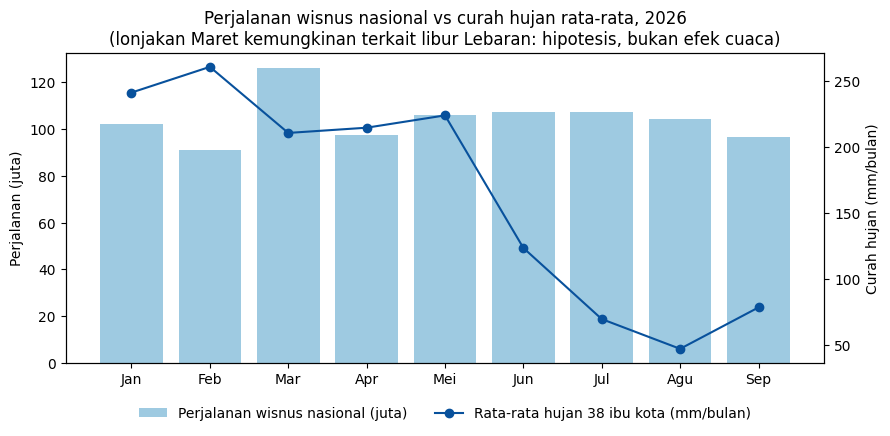

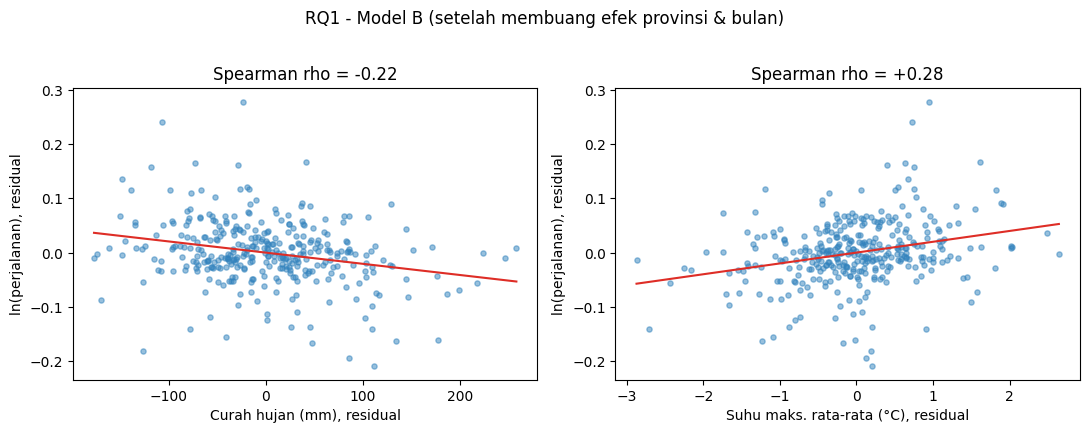

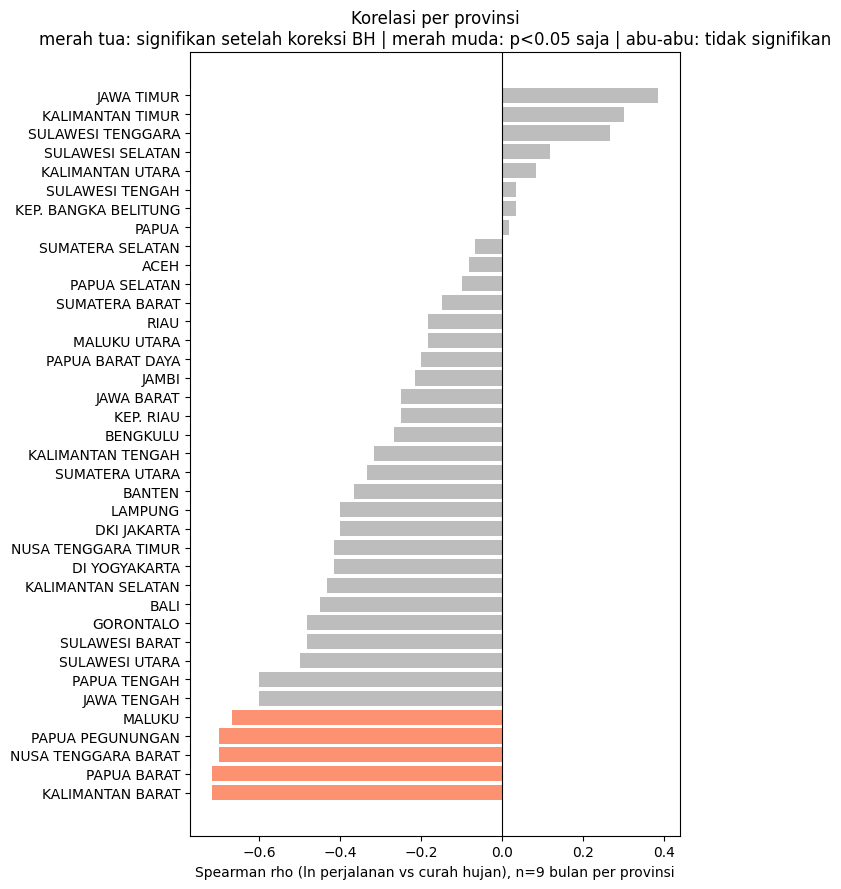

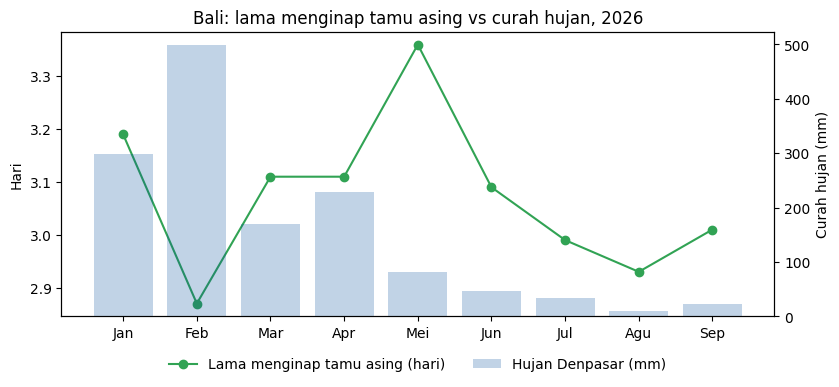

In [47]:
NAMA_BULAN_PENDEK = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

# ---------- Gambar 1: pola nasional ----------
nas = fakta.groupby("periode").agg(hujan=("hujan_total", "mean"), tmax=("tmax_rata", "mean")).join(wisnus_nasional / 1e6)
fig, ax = plt.subplots(figsize=(9, 4.5))
lab = [NAMA_BULAN_PENDEK[p.month - 1] for p in nas.index]
ax.bar(lab, nas["wisnus"], color="#9ecae1", label="Perjalanan wisnus nasional (juta)")
ax.set_ylabel("Perjalanan (juta)")
ax2 = ax.twinx()
ax2.plot(lab, nas["hujan"], color="#08519c", marker="o", label="Rata-rata hujan 38 ibu kota (mm/bulan)")
ax2.set_ylabel("Curah hujan (mm/bulan)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.set_title("Perjalanan wisnus nasional vs curah hujan rata-rata, 2026\n(lonjakan Maret kemungkinan terkait libur Lebaran: hipotesis, bukan efek cuaca)")
plt.tight_layout(); fig.savefig(FIGS / "fig1_pola_nasional.png", dpi=150); plt.show()

# ---------- Gambar 2: sebar efek tetap dua arah ----------
B = pd.DataFrame({c: dua_arah(fakta, c) for c in ["ln_wisnus", "hujan_total", "tmax_rata"]})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, x, judul in zip(axes, ["hujan_total", "tmax_rata"], ["Curah hujan (mm), residual", "Suhu maks. rata-rata (°C), residual"]):
    ax.scatter(B[x], B["ln_wisnus"], s=14, alpha=0.5, color="#3182bd")
    k = np.polyfit(B[x], B["ln_wisnus"], 1)
    xs = np.linspace(B[x].min(), B[x].max(), 50)
    ax.plot(xs, np.polyval(k, xs), color="#de2d26")
    rho = stats.spearmanr(B[x], B["ln_wisnus"])[0]
    ax.set_title(f"Spearman rho = {rho:+.2f}"); ax.set_xlabel(judul); ax.set_ylabel("ln(perjalanan), residual")
fig.suptitle("RQ1 - Model B (setelah membuang efek provinsi & bulan)", y=1.02)
plt.tight_layout(); fig.savefig(FIGS / "fig2_scatter_model_B.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- Gambar 3: rho per provinsi ----------
t = per_prov_hujan.dropna(subset=["rho"]).sort_values("rho")
warna = ["#de2d26" if q < 0.05 else ("#fc9272" if p < 0.05 else "#bdbdbd") for p, q in zip(t["p"], t["p_BH"])]
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(t["provinsi"], t["rho"], color=warna)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Spearman rho (ln perjalanan vs curah hujan), n=9 bulan per provinsi")
ax.set_title("Korelasi per provinsi\nmerah tua: signifikan setelah koreksi BH | merah muda: p<0.05 saja | abu-abu: tidak signifikan")
plt.tight_layout(); fig.savefig(FIGS / "fig3_rho_per_provinsi.png", dpi=150); plt.show()

# ---------- Gambar 4: lama menginap tamu asing - Bali ----------
bali = fakta[fakta["provinsi"] == "BALI"].sort_values("periode")
fig, ax = plt.subplots(figsize=(8.5, 4))
lb = [NAMA_BULAN_PENDEK[p.month - 1] for p in bali["periode"]]
ax.plot(lb, bali["lama_inap_asing"], marker="o", color="#31a354", label="Lama menginap tamu asing (hari)")
ax.set_ylabel("Hari")
ax2 = ax.twinx(); ax2.bar(lb, bali["hujan_total"], alpha=0.25, color="#08519c", label="Hujan Denpasar (mm)")
ax2.set_ylabel("Curah hujan (mm)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.set_title("Bali: lama menginap tamu asing vs curah hujan, 2026")
plt.tight_layout(); fig.savefig(FIGS / "fig4_bali.png", dpi=150); plt.show()

### 6.1 Studi pelengkap (RQ3): kedatangan wisatawan nasional 2025 di 4 bandara besar vs cuaca kota bandara

File Wisnas 2025 memakai **tahun berbeda** (2025) dan **ukuran berbeda** (pintu masuk, bukan provinsi), jadi tidak digabung ke tabel fakta 2026.
Sebagai gantinya dipakai pasangan terpisah: 4 bandara besar dengan cuaca 2025 di sekitar bandara (4 request tambahan).

,pintu,cuaca,n,spearman_rho,p_spearman,p_BH
0,Juanda,hujan_total,12,-0.06,0.85,0.88
1,Juanda,tmax_rata,12,0.15,0.63,0.88
2,Kualanamu,hujan_total,12,-0.05,0.88,0.88
3,Kualanamu,tmax_rata,12,-0.27,0.40,0.88
4,Ngurah Rai,hujan_total,12,0.26,0.42,0.88
5,Ngurah Rai,tmax_rata,12,0.10,0.75,0.88
6,Soekarno Hatta,hujan_total,12,0.17,0.59,0.88
7,Soekarno Hatta,tmax_rata,12,-0.27,0.39,0.88


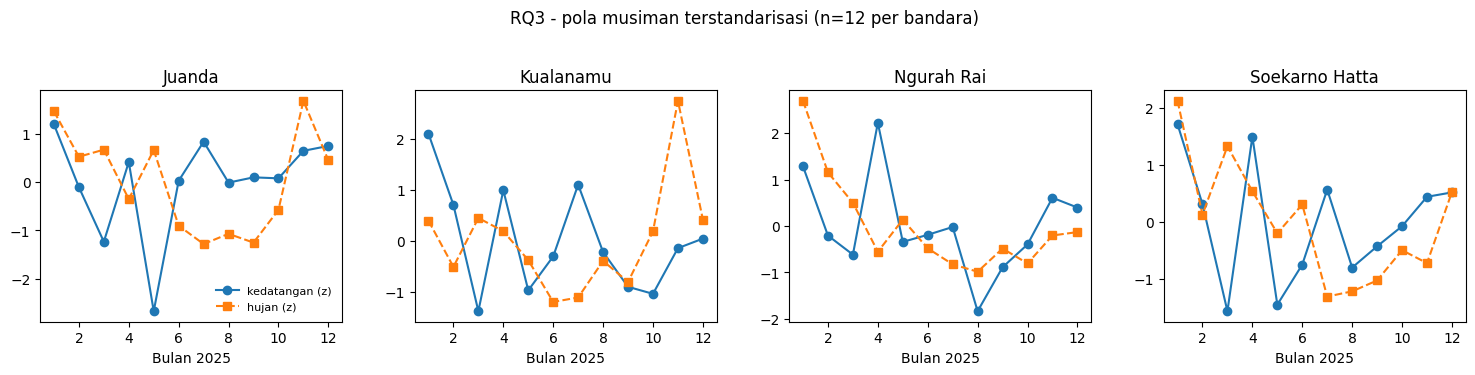

In [48]:
GERBANG = {   # pintu masuk -> (slug, lokasi cuaca, lat, lon); koordinat perkiraan area bandara
    "Ngurah Rai": ("gate-ngurah-rai", "Badung (Bali)", -8.7467, 115.1668),
    "Soekarno Hatta": ("gate-soekarno-hatta", "Tangerang (Banten)", -6.1256, 106.6559),
    "Juanda": ("gate-juanda", "Sidoarjo (Jatim)", -7.3798, 112.7869),
    "Kualanamu": ("gate-kualanamu", "Deli Serdang (Sumut)", 3.6422, 98.8853),
}
S25, E25 = "2025-01-01", "2025-12-31"

gate_long = (wisnas_h[(wisnas_h["tingkat"] == 3) & (wisnas_h["wilayah"].isin(GERBANG)) & (wisnas_h["induk"].str.startswith("A."))]
             .melt(id_vars="wilayah", value_vars=BULAN, var_name="bulan_nama", value_name="kedatangan_wisnas"))
gate_long["periode"] = pd.to_datetime(gate_long["bulan_nama"].map(lambda b: f"2025-{NOMOR_BULAN[b]:02d}-01"))
gate_long = gate_long.rename(columns={"wilayah": "pintu"}).drop(columns="bulan_nama")

fr25 = []
for pintu, (slug, lokasi, lat, lon) in GERBANG.items():
    js, dari = ambil_cuaca(slug, lat, lon, S25, E25)
    if js is None:
        raise RuntimeError(f"Gagal mengambil cuaca untuk {pintu}; jalankan ulang sel ini.")
    d, _ = json_ke_df(js, pintu)
    fr25.append(d)
c25 = pd.concat(fr25, ignore_index=True).rename(columns={"kunci": "pintu"})
c25["periode"] = c25["tanggal"].dt.to_period("M").dt.to_timestamp()
c25_bulanan = (c25.groupby(["pintu", "periode"])
               .agg(tmax_rata=("tmax", "mean"), hujan_total=("hujan", "sum"), n_hari=("tanggal", "nunique")).reset_index())

gate = gate_long.merge(c25_bulanan, on=["pintu", "periode"], how="left", validate="one_to_one")
assert len(gate) == 4 * 12 and gate["hujan_total"].notna().all()
gate["ln_kedatangan"] = np.log(gate["kedatangan_wisnas"])

baris = []
for pintu, g in gate.groupby("pintu"):
    for x in ["hujan_total", "tmax_rata"]:
        rho, p = stats.spearmanr(g[x], g["ln_kedatangan"])
        baris.append(dict(pintu=pintu, cuaca=x, n=len(g), spearman_rho=rho, p_spearman=p))
hasil_gate = pd.DataFrame(baris)
hasil_gate["p_BH"] = bh_adjust(hasil_gate["p_spearman"])
display(hasil_gate)
hasil_gate.to_csv(PROCESSED / "hasil_korelasi_gerbang_2025.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True)
for ax, (pintu, g) in zip(axes, gate.groupby("pintu")):
    g = g.sort_values("periode")
    z = lambda s: (s - s.mean()) / s.std(ddof=0)
    ax.plot(range(1, 13), z(g["ln_kedatangan"]), marker="o", label="kedatangan (z)")
    ax.plot(range(1, 13), z(g["hujan_total"]), marker="s", ls="--", label="hujan (z)")
    ax.set_title(pintu); ax.set_xlabel("Bulan 2025")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("RQ3 - pola musiman terstandarisasi (n=12 per bandara)", y=1.03)
plt.tight_layout(); fig.savefig(FIGS / "fig5_gerbang_2025.png", dpi=150, bbox_inches="tight"); plt.show()

In [49]:
def kekuatan(rho):
    a = abs(rho)
    return "sangat lemah / dapat diabaikan" if a < 0.1 else "lemah" if a < 0.3 else "sedang" if a < 0.5 else "kuat"

print("=== RINGKASAN OTOMATIS (dihitung dari data, bukan ditulis tangan) ===\n")
for _, r in hasil[hasil["model"].str.startswith("B")].iterrows():
    print(f"- {r['hasil']:<24s} | {r['subset']:<24s} | {r['cuaca']:<12s} rho={r['spearman_rho']:+.2f} "
          f"(n={r['n']}, p={r['p_spearman']:.3f}) -> {kekuatan(r['spearman_rho'])}, "
          f"{'signifikan' if r['p_spearman'] < 0.05 else 'tidak signifikan'} pada alpha 5%")
print("\nRQ3 (n=12 per bandara):")
for _, r in hasil_gate.iterrows():
    print(f"- {r['pintu']:<15s} {r['cuaca']:<12s} rho={r['spearman_rho']:+.2f} (p={r['p_spearman']:.3f}; q_BH={r['p_BH']:.3f}) -> {kekuatan(r['spearman_rho'])}")
print("\nCatatan: tulis kesimpulan Anda sendiri dari angka di atas. Gunakan kata 'berasosiasi', bukan 'menyebabkan'.")

=== RINGKASAN OTOMATIS (dihitung dari data, bukan ditulis tangan) ===

- ln_wisnus                | semua provinsi           | hujan_total  rho=-0.22 (n=342, p=0.000) -> lemah, signifikan pada alpha 5%
- ln_wisnus                | semua provinsi           | hari_hujan   rho=-0.18 (n=342, p=0.001) -> lemah, signifikan pada alpha 5%
- ln_wisnus                | semua provinsi           | tmax_rata    rho=+0.28 (n=342, p=0.000) -> lemah, signifikan pada alpha 5%
- lama_inap_asing_bersih   | semua (kecuali nilai 0)  | hujan_total  rho=-0.06 (n=341, p=0.240) -> sangat lemah / dapat diabaikan, tidak signifikan pada alpha 5%
- lama_inap_asing_bersih   | semua (kecuali nilai 0)  | hari_hujan   rho=-0.01 (n=341, p=0.801) -> sangat lemah / dapat diabaikan, tidak signifikan pada alpha 5%
- lama_inap_asing_bersih   | semua (kecuali nilai 0)  | tmax_rata    rho=-0.03 (n=341, p=0.594) -> sangat lemah / dapat diabaikan, tidak signifikan pada alpha 5%
- lama_inap_asing_bersih   | tanpa outlier        

### 6.2 Keterbatasan (wajib dicantumkan di laporan)

1. **Asal vs tujuan.** Wisnus dicatat menurut provinsi **asal** perjalanan, sedangkan cuaca yang berpengaruh pada keputusan wisata sering cuaca **tujuan**. Cuaca di provinsi asal hanya *proxy* kasar.
2. **Satu kota mewakili satu provinsi.** Ibu kota provinsi tidak mewakili cuaca seluruh provinsi (pegunungan vs pesisir, pulau besar).
3. **Hanya 9 bulan (n=9 per provinsi).** Daya uji rendah; korelasi per provinsi sangat tidak stabil. Karena itu hasil per provinsi dikoreksi BH dan lebih mengandalkan model gabungan.
4. **Perancu musiman & libur** (Lebaran, libur sekolah, cuti bersama) bergerak serempak di semua provinsi; Model B menghapus efek serempak ini, tetapi tidak menghapus perancu yang berbeda antarprovinsi.
5. **Lama menginap = hanya tamu ASING di hotel berbintang.** Untuk provinsi non-wisata mancanegara (mis. banyak provinsi di Papua) jumlah tamu sangat kecil sehingga rata-rata mudah ekstrem (misal 25,9 hari). Jumlah tamu tidak tersedia pada file ini, jadi bobot tidak dapat dikoreksi.
6. **ERA5 adalah reanalisis (grid)**, bukan pengukuran stasiun BMKG.
7. **Korelasi bukan kausalitas.**

---
## Bagian 7. Ekspor Hasil, Kamus Data & Sitasi

In [50]:
kolom_fakta = ["provinsi", "kode_iso", "ibu_kota", "periode", "wisnus", "ln_wisnus", "lama_inap_asing",
               "lama_inap_asing_bersih", "outlier_inap", "tmax_rata", "tmax_puncak", "hujan_total", "hari_hujan",
               "n_hari", "penduduk", "luas_km2"]
fakta[kolom_fakta].to_csv(PROCESSED / "fakta_pariwisata_cuaca_2026.csv", index=False)
dim_provinsi.to_csv(PROCESSED / "dim_provinsi.csv", index=False)
gate.to_csv(PROCESSED / "gerbang_wisnas_cuaca_2025.csv", index=False)
cuaca_harian.drop(columns="periode").to_csv(PROCESSED / "cuaca_harian_38_ibu_kota.csv", index=False)

kamus = pd.DataFrame([
    ("provinsi", "Nama provinsi (kunci gabung; ejaan BPS)", "-", "BPS"),
    ("periode", "Awal bulan pengamatan", "tanggal", "BPS"),
    ("wisnus", "Jumlah perjalanan wisatawan nusantara menurut provinsi ASAL", "perjalanan", "BPS (CSV)"),
    ("ln_wisnus", "Logaritma natural wisnus", "-", "turunan"),
    ("lama_inap_asing", "Rata-rata lama menginap tamu asing di hotel berbintang (nilai asli BPS)", "hari", "BPS (CSV)"),
    ("lama_inap_asing_bersih", "Seperti di atas, nilai 0 diubah menjadi NaN", "hari", "turunan"),
    ("outlier_inap", "True jika |modified z-score| > 3,5", "bool", "turunan"),
    ("tmax_rata", "Rata-rata suhu maksimum harian dalam bulan, ibu kota provinsi", "°C", "Open-Meteo (ERA5)"),
    ("tmax_puncak", "Suhu maksimum tertinggi dalam bulan", "°C", "Open-Meteo (ERA5)"),
    ("hujan_total", "Total curah hujan bulan itu", "mm", "Open-Meteo (ERA5)"),
    ("hari_hujan", "Jumlah hari dengan hujan >= 1 mm", "hari", "turunan"),
    ("n_hari", "Jumlah hari data cuaca tersedia pada bulan itu", "hari", "turunan"),
    ("penduduk / luas_km2", "Penduduk dan luas provinsi dari tabel Wikipedia", "jiwa / km2", "Wikipedia (scraping)"),
], columns=["kolom", "deskripsi", "satuan", "sumber"])
kamus.to_csv(PROCESSED / "kamus_data.csv", index=False)
display(kamus)
print("\nFile keluaran:")
for p in sorted(list(PROCESSED.glob("*.csv")) + list(FIGS.glob("*.png"))):
    print(f"  {p.relative_to(BASE)}  ({p.stat().st_size/1024:.1f} KB)")

,kolom,deskripsi,satuan,sumber
0,provinsi,Nama provinsi (kunci gabung; ejaan BPS),-,BPS
1,periode,Awal bulan pengamatan,tanggal,BPS
2,wisnus,Jumlah perjalanan wisatawan nusantara menurut provinsi ASAL,perjalanan,BPS (CSV)
3,ln_wisnus,Logaritma natural wisnus,-,turunan
4,lama_inap_asing,Rata-rata lama menginap tamu asing di hotel berbintang (nilai asli BPS),hari,BPS (CSV)
5,lama_inap_asing_bersih,"Seperti di atas, nilai 0 diubah menjadi NaN",hari,turunan
6,outlier_inap,"True jika |modified z-score| > 3,5",bool,turunan
7,tmax_rata,"Rata-rata suhu maksimum harian dalam bulan, ibu kota provinsi",°C,Open-Meteo (ERA5)
8,tmax_puncak,Suhu maksimum tertinggi dalam bulan,°C,Open-Meteo (ERA5)
9,hujan_total,Total curah hujan bulan itu,mm,Open-Meteo (ERA5)



File keluaran:
  data/processed/cuaca_harian_38_ibu_kota.csv  (338.1 KB)
  data/processed/dim_provinsi.csv  (3.8 KB)
  data/processed/fakta_pariwisata_cuaca_2026.csv  (45.9 KB)
  data/processed/gerbang_wisnas_cuaca_2025.csv  (3.5 KB)
  data/processed/hasil_korelasi_gabungan.csv  (2.9 KB)
  data/processed/hasil_korelasi_gerbang_2025.csv  (0.7 KB)
  data/processed/kamus_data.csv  (0.9 KB)
  data/processed/korelasi_per_provinsi.csv  (6.8 KB)
  outputs/figures/fig1_pola_nasional.png  (84.4 KB)
  outputs/figures/fig2_scatter_model_B.png  (117.6 KB)
  outputs/figures/fig3_rho_per_provinsi.png  (145.6 KB)
  outputs/figures/fig4_bali.png  (68.7 KB)
  outputs/figures/fig5_gerbang_2025.png  (131.3 KB)


### Sitasi & atribusi

* Badan Pusat Statistik. *Jumlah Perjalanan Wisatawan Nusantara Menurut Provinsi Asal (Perjalanan)*. Tabel Statistik. Diakses pada **ISI TANGGAL AKSES**, dari https://www.bps.go.id/id/statistics-table/2/MTE4OSMy/jumlah-perjalanan-wisatawan-nusantara-menurut-provinsi-asal--perjalanan-.html
* Badan Pusat Statistik. *Rata-rata Lama Menginap Tamu Asing pada Hotel Berbintang di Indonesia (Hari)*. Tabel Statistik. Diakses pada **ISI TANGGAL AKSES**, dari **ISI URL**.
* Badan Pusat Statistik. *Jumlah Perjalanan Wisatawan Nasional (Perjalanan) menurut Pintu Masuk Kedatangan*. Tabel Statistik. Diakses pada **ISI TANGGAL AKSES**, dari **ISI URL**.
* Open-Meteo.com. *Historical Weather API* (data cuaca berlisensi CC BY 4.0, bersumber dari reanalisis ERA5). https://open-meteo.com/ , diakses pada **ISI TANGGAL**. Zippenfenig, P. (2023). *Open-Meteo.com Weather API* [Software]. Zenodo. https://doi.org/10.5281/zenodo.7970649
* Wikipedia. *Provinces of Indonesia*. https://en.wikipedia.org/wiki/Provinces_of_Indonesia , diakses pada **ISI TANGGAL** (teks CC BY-SA 4.0).

*(Sesuaikan format sitasi dengan pedoman kampus.)*

### Checklist kesesuaian dengan ketentuan tugas

| Ketentuan | Dipenuhi di |
|---|---|
| File BPS >= 100 baris, `read_csv` dengan `encoding`/`sep` tepat, profil data | Bagian 1 (342 baris long per tabel) |
| Estimasi storage 1 tahun + rumus + asumsi | Bagian 1 & validasi di Bagian 3 |
| Audit lisensi, audit PII/quasi-identifier, checklist etika 9 butir | Bagian 2 |
| API: `requests`, `User-Agent` berisi e-mail kampus, `timeout`, `time.sleep`, `try-except`, DataFrame >= 30 baris | Bagian 3 (sekitar 10 ribu baris harian: 38 provinsi x ~273 hari) |
| Scraping etis: `robots.txt`, User-Agent, jeda, parsing tabel HTML | Bagian 4 |
| `pd.merge` + `validate`, bukti tidak ada duplikasi, provenance (URL, tanggal akses, lisensi, MD5) di `data/raw` | Bagian 5 |